# Telco Customer Churn Prediction

**Goal:** predict which customers are likely to churn (leave) within the next month, so the sales & marketing team can offer them retention incentives.

**Data:** [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) (IBM sample data) · **Target:** `Churn` (Yes/No)

In [1]:
%config InlineBackend.figure_formats = ["retina"]

import pandas as pd
from sklearn.model_selection import train_test_split

from churn import config
from churn.ablation import ablation_table, run_ablation, step_effects
from churn.data import clean, column_overview, load_raw, quality_checks, split_features_target
from churn.eda import association_matrix, association_with_churn, format_p_value
from churn.evaluation import (
    comparison_table,
    cross_validate_models,
    holdout_decisions,
    holdout_probabilities,
    holdout_ranking,
    select_model,
)
from churn.explain import explain, odds_ratios, typical_flagged_churner
from churn.features import FeatureEngineer
from churn.models import best_models, tune_models, tuning_results
from churn.pipeline import build_preprocessor, compare_skewness
from churn.plots import (
    plot_ablation,
    plot_association_matrix,
    plot_calibration_and_gains,
    plot_churn_by_tenure_and_contract,
    plot_churn_heatmap,
    plot_churn_rate_by_category,
    plot_confusion_matrices,
    plot_holdout_curves,
    plot_model_comparison,
    plot_new_features,
    plot_numeric_distributions,
    plot_odds_ratios,
    plot_shap_summary,
    plot_shap_waterfall,
    plot_target_distribution,
    plot_threshold_metrics,
    set_theme,
)
from churn.threshold import metrics_by_threshold, near_optimal, tune_threshold

pd.set_option("display.max_columns", 30)
set_theme()

## 1. Data loading & cleaning

The CSV is downloaded once into `data/` and verified by its SHA-256 checksum, so every run uses exactly the same data.

In [2]:
raw = load_raw()
print(f"{len(raw):,} customers × {raw.shape[1]} columns")
raw.head()

7,043 customers × 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Each row is one customer: demographics (`gender`, `SeniorCitizen`, `Partner`, `Dependents`), subscribed services (phone, internet and its add-ons), account information (`tenure` in months, `Contract`, billing, charges) and the target `Churn`: whether the customer left within the last month.

In [3]:
column_overview(raw)

,dtype,unique,missing,examples
customerID,str,7043,0,"7590-VHVEG, 5575-GNVDE, 3668-QPYBK"
gender,str,2,0,"Female, Male"
SeniorCitizen,int64,2,0,"0, 1"
Partner,str,2,0,"Yes, No"
Dependents,str,2,0,"No, Yes"
tenure,int64,73,0,"1, 34, 2"
PhoneService,str,2,0,"No, Yes"
MultipleLines,str,3,0,"No phone service, No, Yes"
InternetService,str,3,0,"DSL, Fiber optic, No"
OnlineSecurity,str,3,0,"No, Yes, No internet service"


**Data-type issue:** `TotalCharges` holds amounts but is stored as text (`str`), and the overview reports no missing values. The reason is 11 values that are a single space – hidden missing values. All of them belong to customers with `tenure` = 0: brand-new customers who have not been billed yet.

In [4]:
blank = raw["TotalCharges"].str.strip() == ""
raw.loc[blank, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No


**Other checks:** no missing values and no duplicate IDs. 22 rows are identical apart from the ID; all are tenure-1 basic plans, so they are plausibly different customers and are kept.

In [5]:
quality_checks(raw)

,count
missing values,0
duplicate customer IDs,0
blank TotalCharges,11
rows identical apart from the ID,22


**Cleaning** (`churn.data.clean`):

- `TotalCharges` → number; the 11 blanks → 0, the true amount for customers not billed yet (keeps all rows)
- `customerID` dropped: an identifier carries no predictive signal
- `SeniorCitizen` 0/1 → No/Yes, like all other binary columns

In [6]:
df = clean(raw)
df[config.NUMERIC_COLUMNS].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.4,24.6,0.0,9.0,29.0,55.0,72.0
MonthlyCharges,7043.0,64.8,30.1,18.2,35.5,70.4,89.8,118.8
TotalCharges,7043.0,2279.7,2266.8,0.0,398.6,1394.6,3786.6,8684.8


## 2. Exploratory data analysis

All plots use one convention: **blue = churned customers / churn rate** (darker = higher), **gray = customers who stayed**.

### 2.1 Target distribution

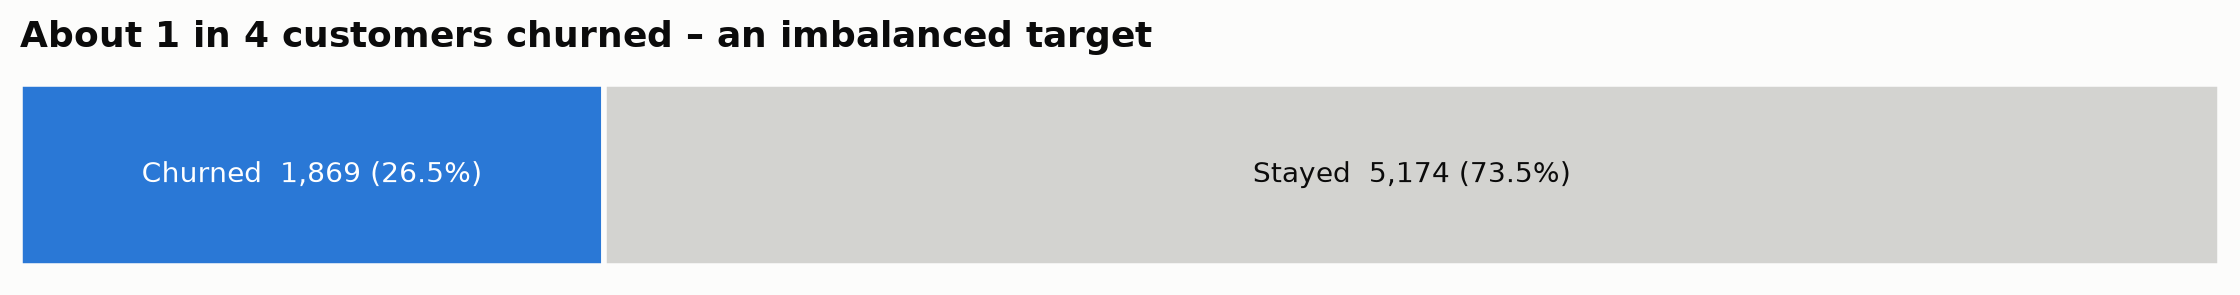

In [7]:
plot_target_distribution(df, "About 1 in 4 customers churned – an imbalanced target");

26.5 % of customers churned (≈ 1 : 2.8). Always predicting "no churn" would already be 73.5 % accurate, so accuracy is misleading here; section 4 introduces metrics that focus on the churn class.

### 2.2 Categorical features

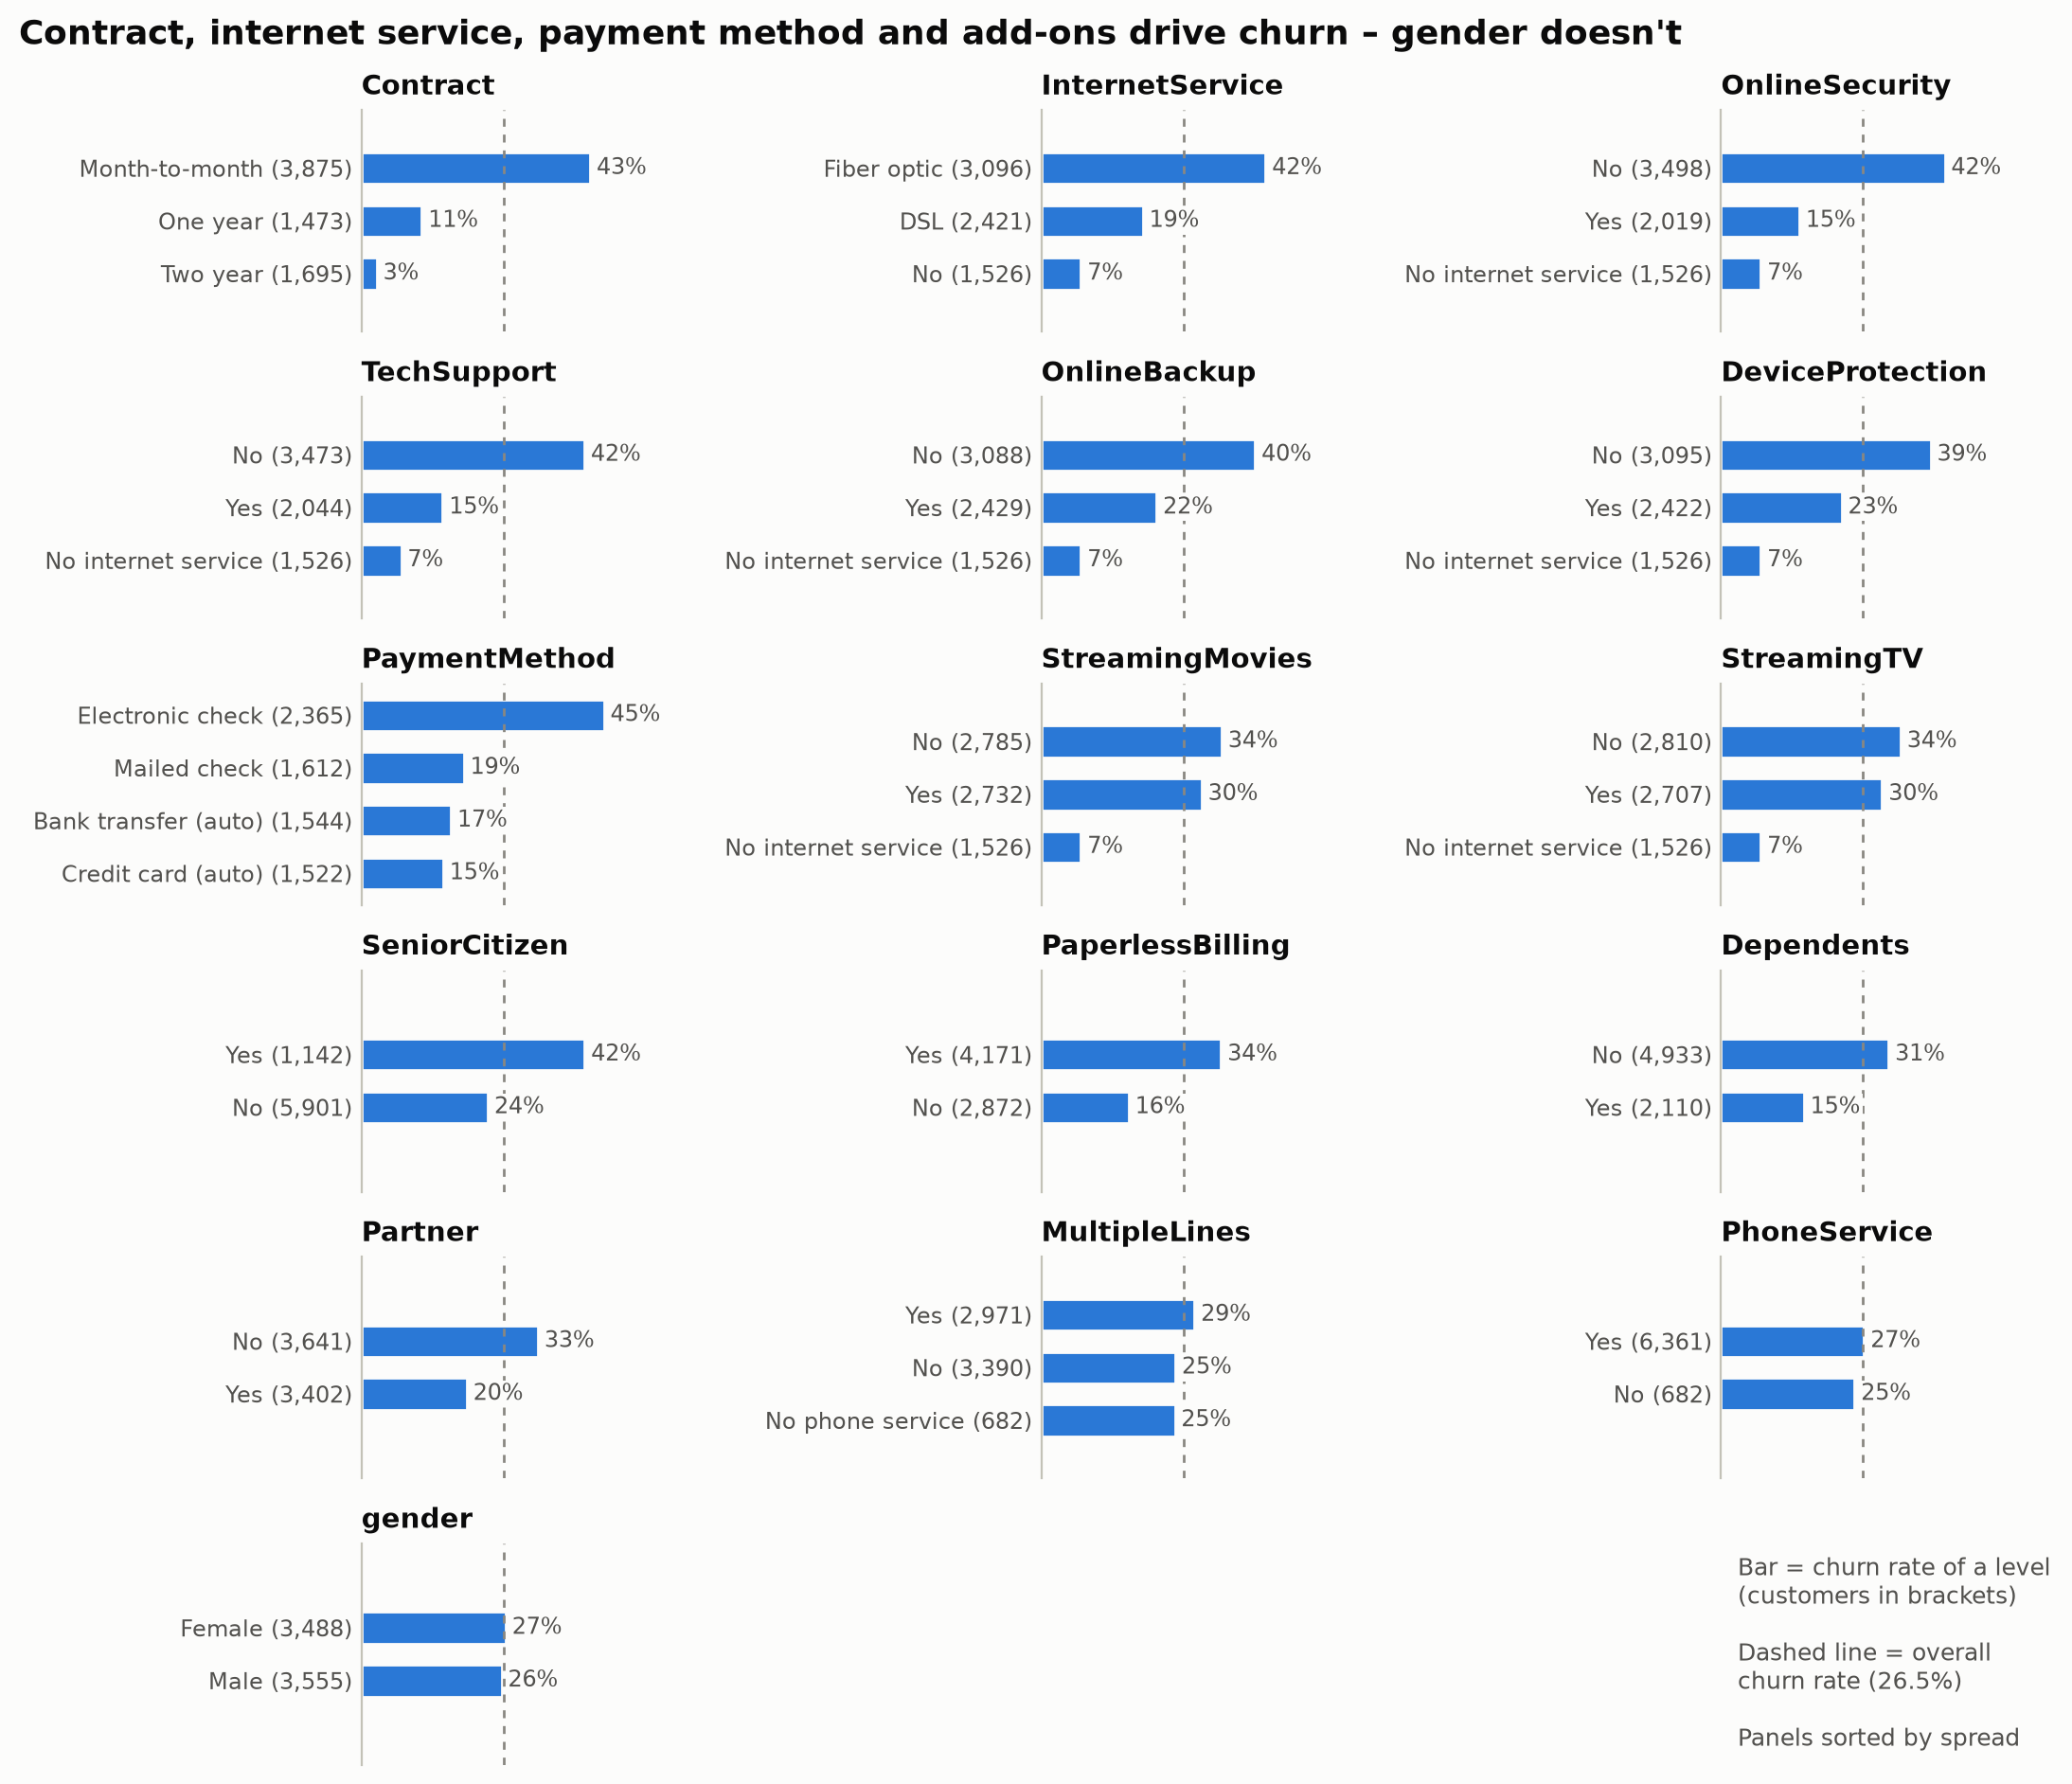

In [8]:
plot_churn_rate_by_category(
    df,
    config.CATEGORICAL_COLUMNS,
    "Contract, internet service, payment method and add-ons drive churn – gender doesn't",
);

- **Contract:** month-to-month customers churn 15× more often than two-year customers (43 % vs 3 %).
- **Internet service:** fiber optic 42 % vs DSL 19 %; customers without internet rarely churn (7 %).
- **Add-ons:** without online security or tech support ~42 % churn, with them ~15 %; streaming barely matters.
- **Payment & billing:** electronic check 45 % vs 15–19 % for the other methods; paperless billing 34 % vs 16 %.
- **Demographics:** seniors 42 % vs 24 %; customers without partner or dependents churn 1.7–2× more often.
- **No effect:** gender and phone service sit at the overall rate.
- The "No internet service" level (7 %) is the same 1,526 customers in six panels.

**Measuring the association: chi² test and Cramér's V**

Both start from a *contingency table* that counts customers per feature level and outcome. If churn were unrelated to the feature, every level would churn at the overall rate of 26.5 %. That gives *expected* counts to compare with the *observed* ones, e.g. for `Contract`:

| Contract | Customers | Churned (observed) | Churned if unrelated (expected) |
|---|---:|---:|---:|
| Month-to-month | 3,875 | 1,655 | 1,028 |
| One year | 1,473 | 166 | 391 |
| Two year | 1,695 | 48 | 450 |

**Chi² statistic:** adds up the gaps between observed (*O*) and expected (*E*) counts over all cells (churned *and* stayed), squared and scaled by the expected count:

$$\chi^2 = \sum \frac{(O - E)^2}{E}$$

`Contract`: 1,185; `gender`: 0.5.

**p-value:** the probability of a χ² at least this large *by pure chance* if churn really were unrelated to the feature. Small values (conventionally < 0.05) mean the differences are not plausibly random noise. It answers *whether* there is an association, not *how strong* it is: with 7,043 customers even small differences become significant, and the strongest give astronomically small p-values (`Contract`: 6e-258).

**Cramér's V:** the *strength* of the association, i.e. χ² rescaled to 0–1 so that it no longer grows with the number of customers *n*:

$$V = \sqrt{\frac{\chi^2}{n\,(k-1)}}$$

where *k* is the smaller dimension of the table (2 here, as churn is Yes/No). 0 = every level churns at the same rate, 1 = the feature fully determines churn. Rule of thumb (Cohen): ≈ 0.1 weak, ≈ 0.3 moderate, ≥ 0.5 strong. `Contract`: √(1,185 / 7,043) = 0.41; `gender`: 0.01.

Numeric features are first cut into five equally sized groups (quintiles). `riskiest_level` is the level with the highest churn rate.

In [9]:
association_with_churn(df).style.format(
    {"cramers_v": "{:.2f}", "p_value": format_p_value, "its_churn_rate": "{:.1%}"}
)

,cramers_v,p_value,riskiest_level,its_churn_rate
feature,,,,
Contract,0.41,6e-258,Month-to-month,42.7%
tenure,0.37,2e-203,0–6,52.9%
OnlineSecurity,0.35,3e-185,No,41.8%
TechSupport,0.34,1e-180,No,41.6%
InternetService,0.32,1e-159,Fiber optic,41.9%
PaymentMethod,0.30,4e-140,Electronic check,45.3%
OnlineBackup,0.29,2e-131,No,39.9%
DeviceProtection,0.28,6e-122,No,39.1%
TotalCharges,0.24,1e-88,0–265,45.8%


Contract, tenure, the support add-ons, internet service and payment method are the strongest signals (V ≈ 0.3–0.4, moderate). Nearly every difference is significant, except gender (p = 0.49) and phone service (p = 0.34), which show no association at all (V ≈ 0.01).

### 2.3 Numeric features

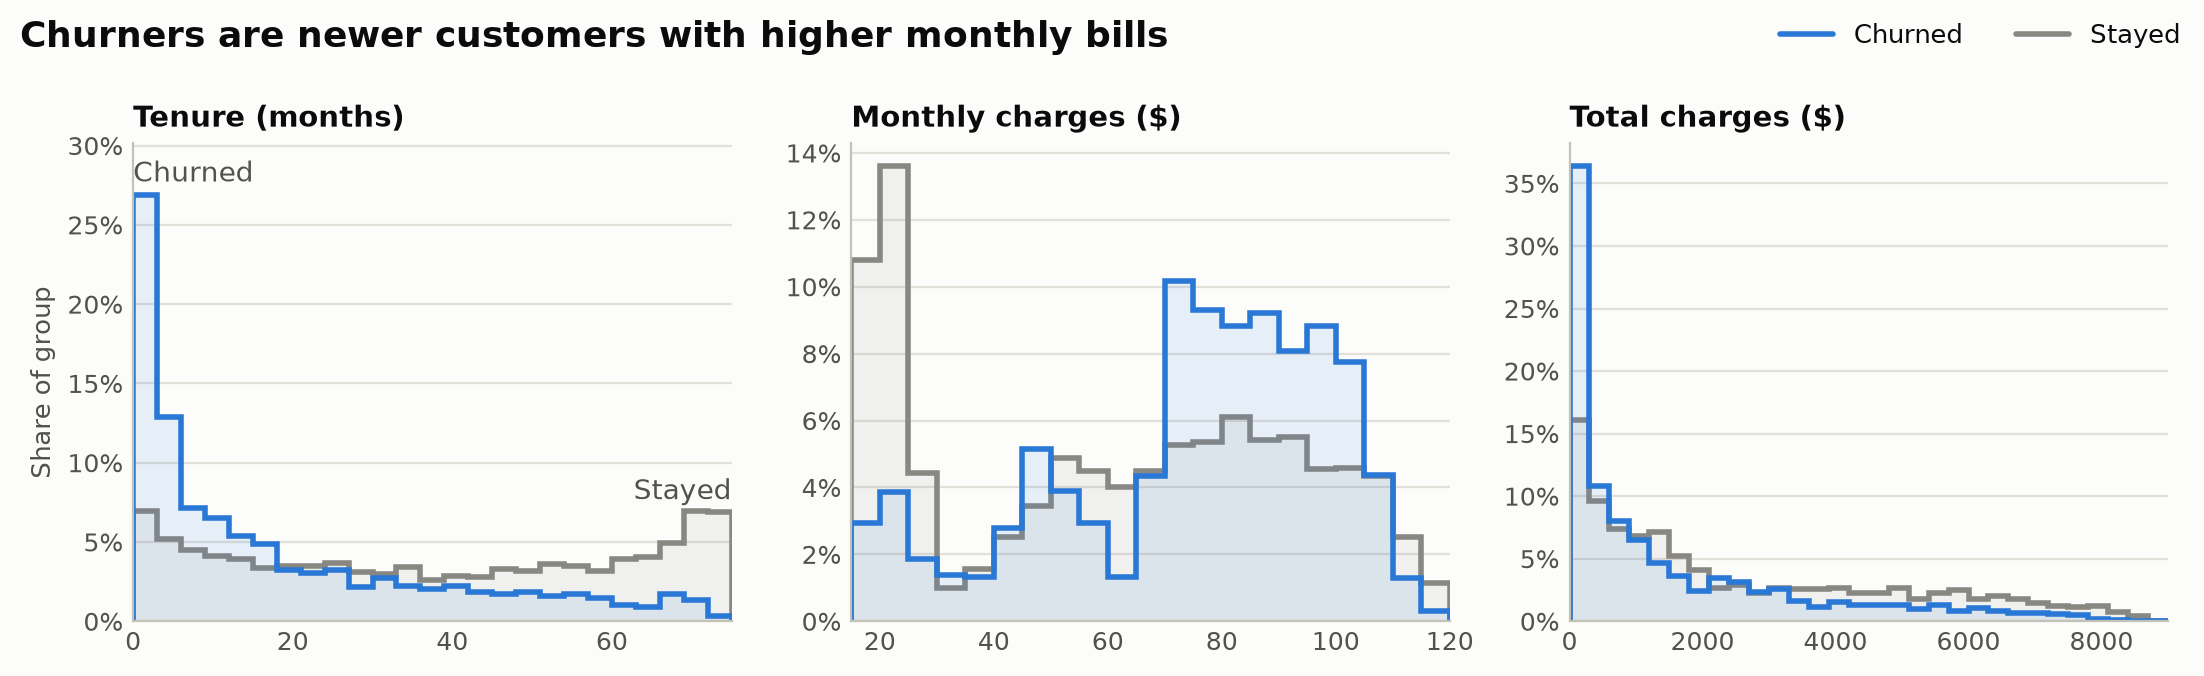

In [10]:
plot_numeric_distributions(df, "Churners are newer customers with higher monthly bills");

Churners are concentrated in their first months (median tenure 10 vs 38 months) and at monthly charges of USD 70–105, typical for fiber optic plans (median USD 92). Their lower total charges mostly reflect the short tenure.

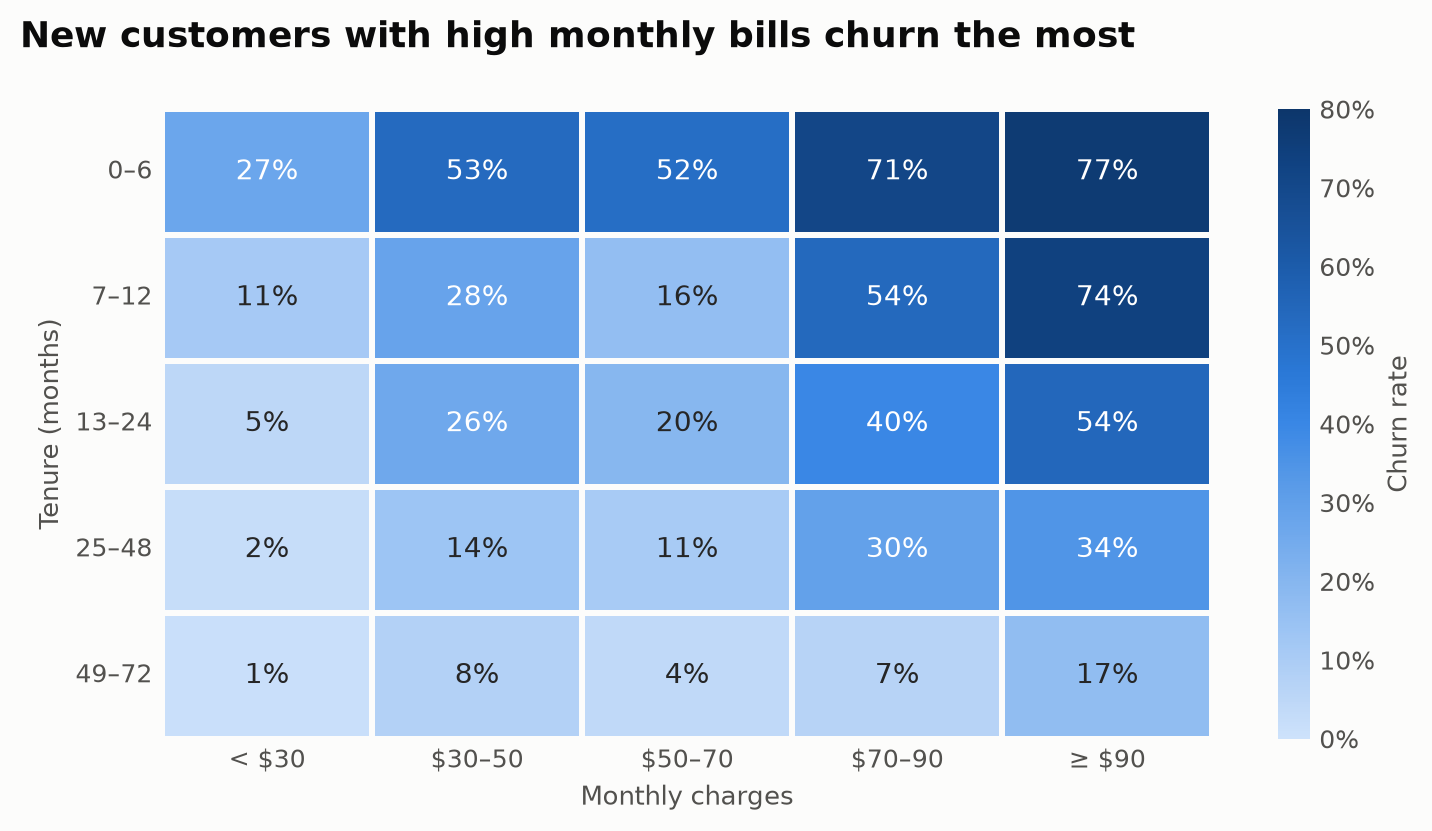

In [11]:
plot_churn_heatmap(df, "New customers with high monthly bills churn the most");

The two effects add up: 77 % of customers in their first 6 months with bills ≥ USD 90 churned, vs 1 % of customers with more than 4 years of tenure paying < USD 30.

### 2.4 Tenure and contract type

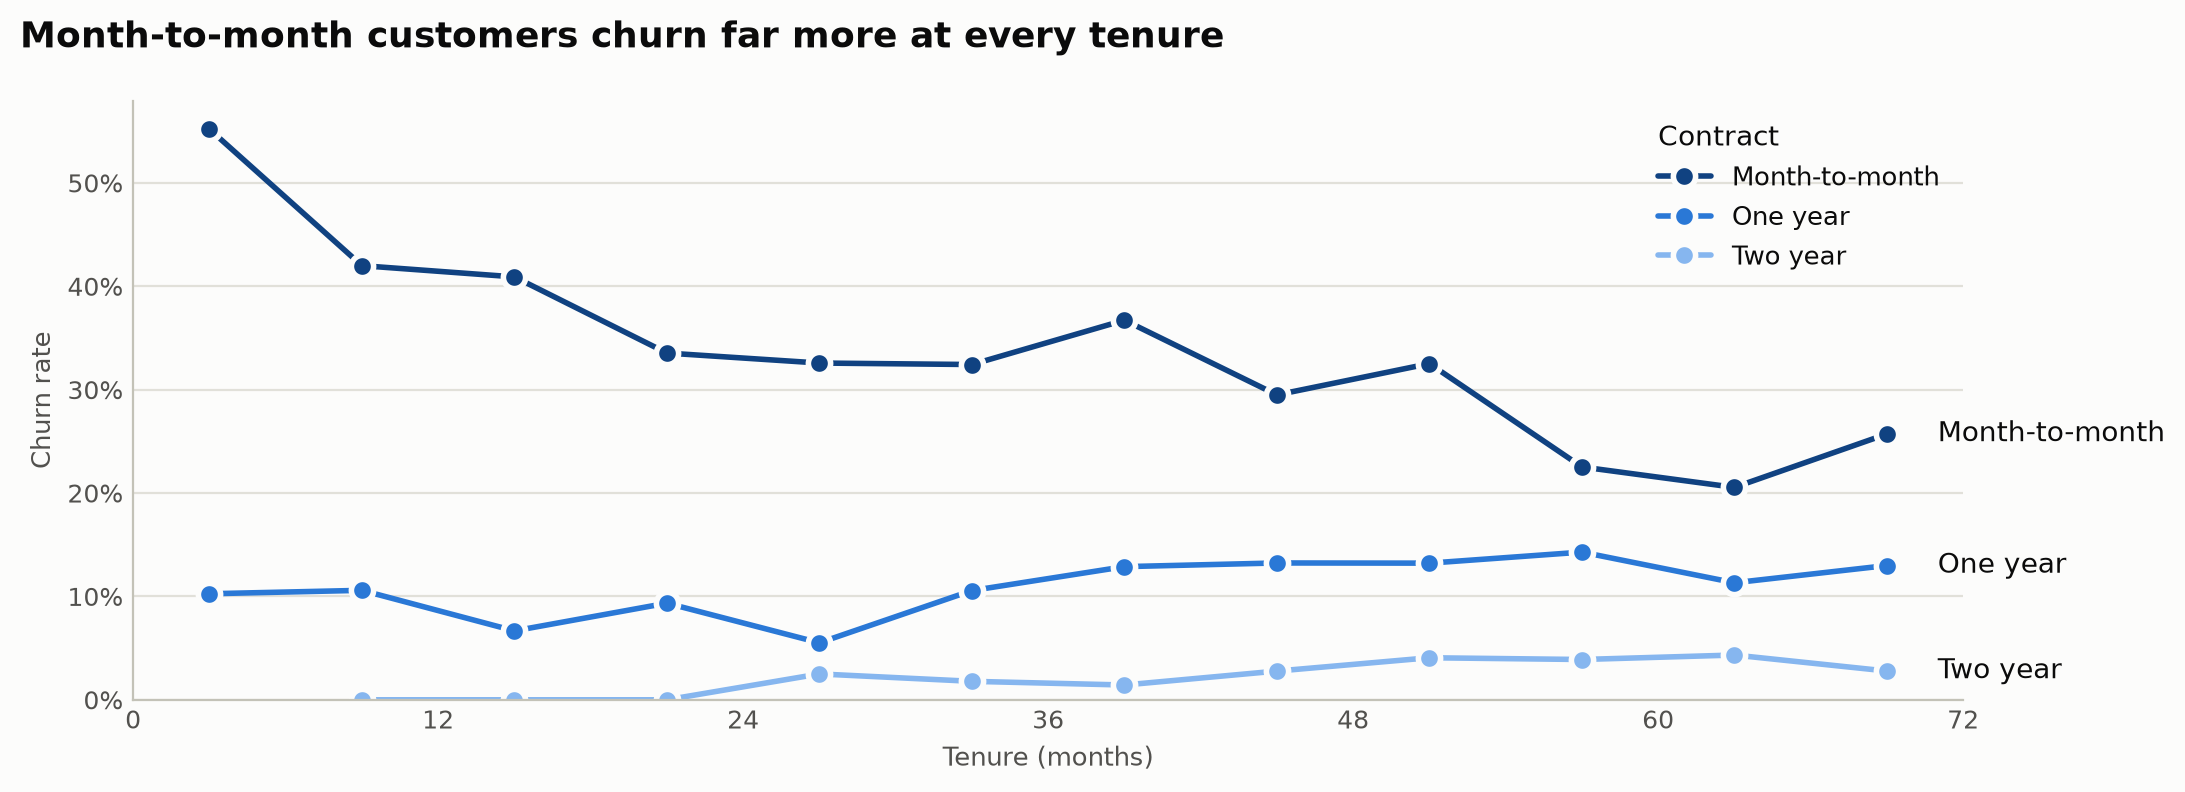

In [12]:
plot_churn_by_tenure_and_contract(df, "Month-to-month customers churn far more at every tenure");

Month-to-month churn drops from 55 % in the first half-year to 21–26 % after 4½ years, yet stays far above one-year (≤ 14 %) and two-year (≤ 4 %) contracts at every tenure: contract length matters on top of tenure.

### 2.5 Associations between features

The same Cramér's V, computed for every pair of features (*k* = the smaller number of levels of the two).

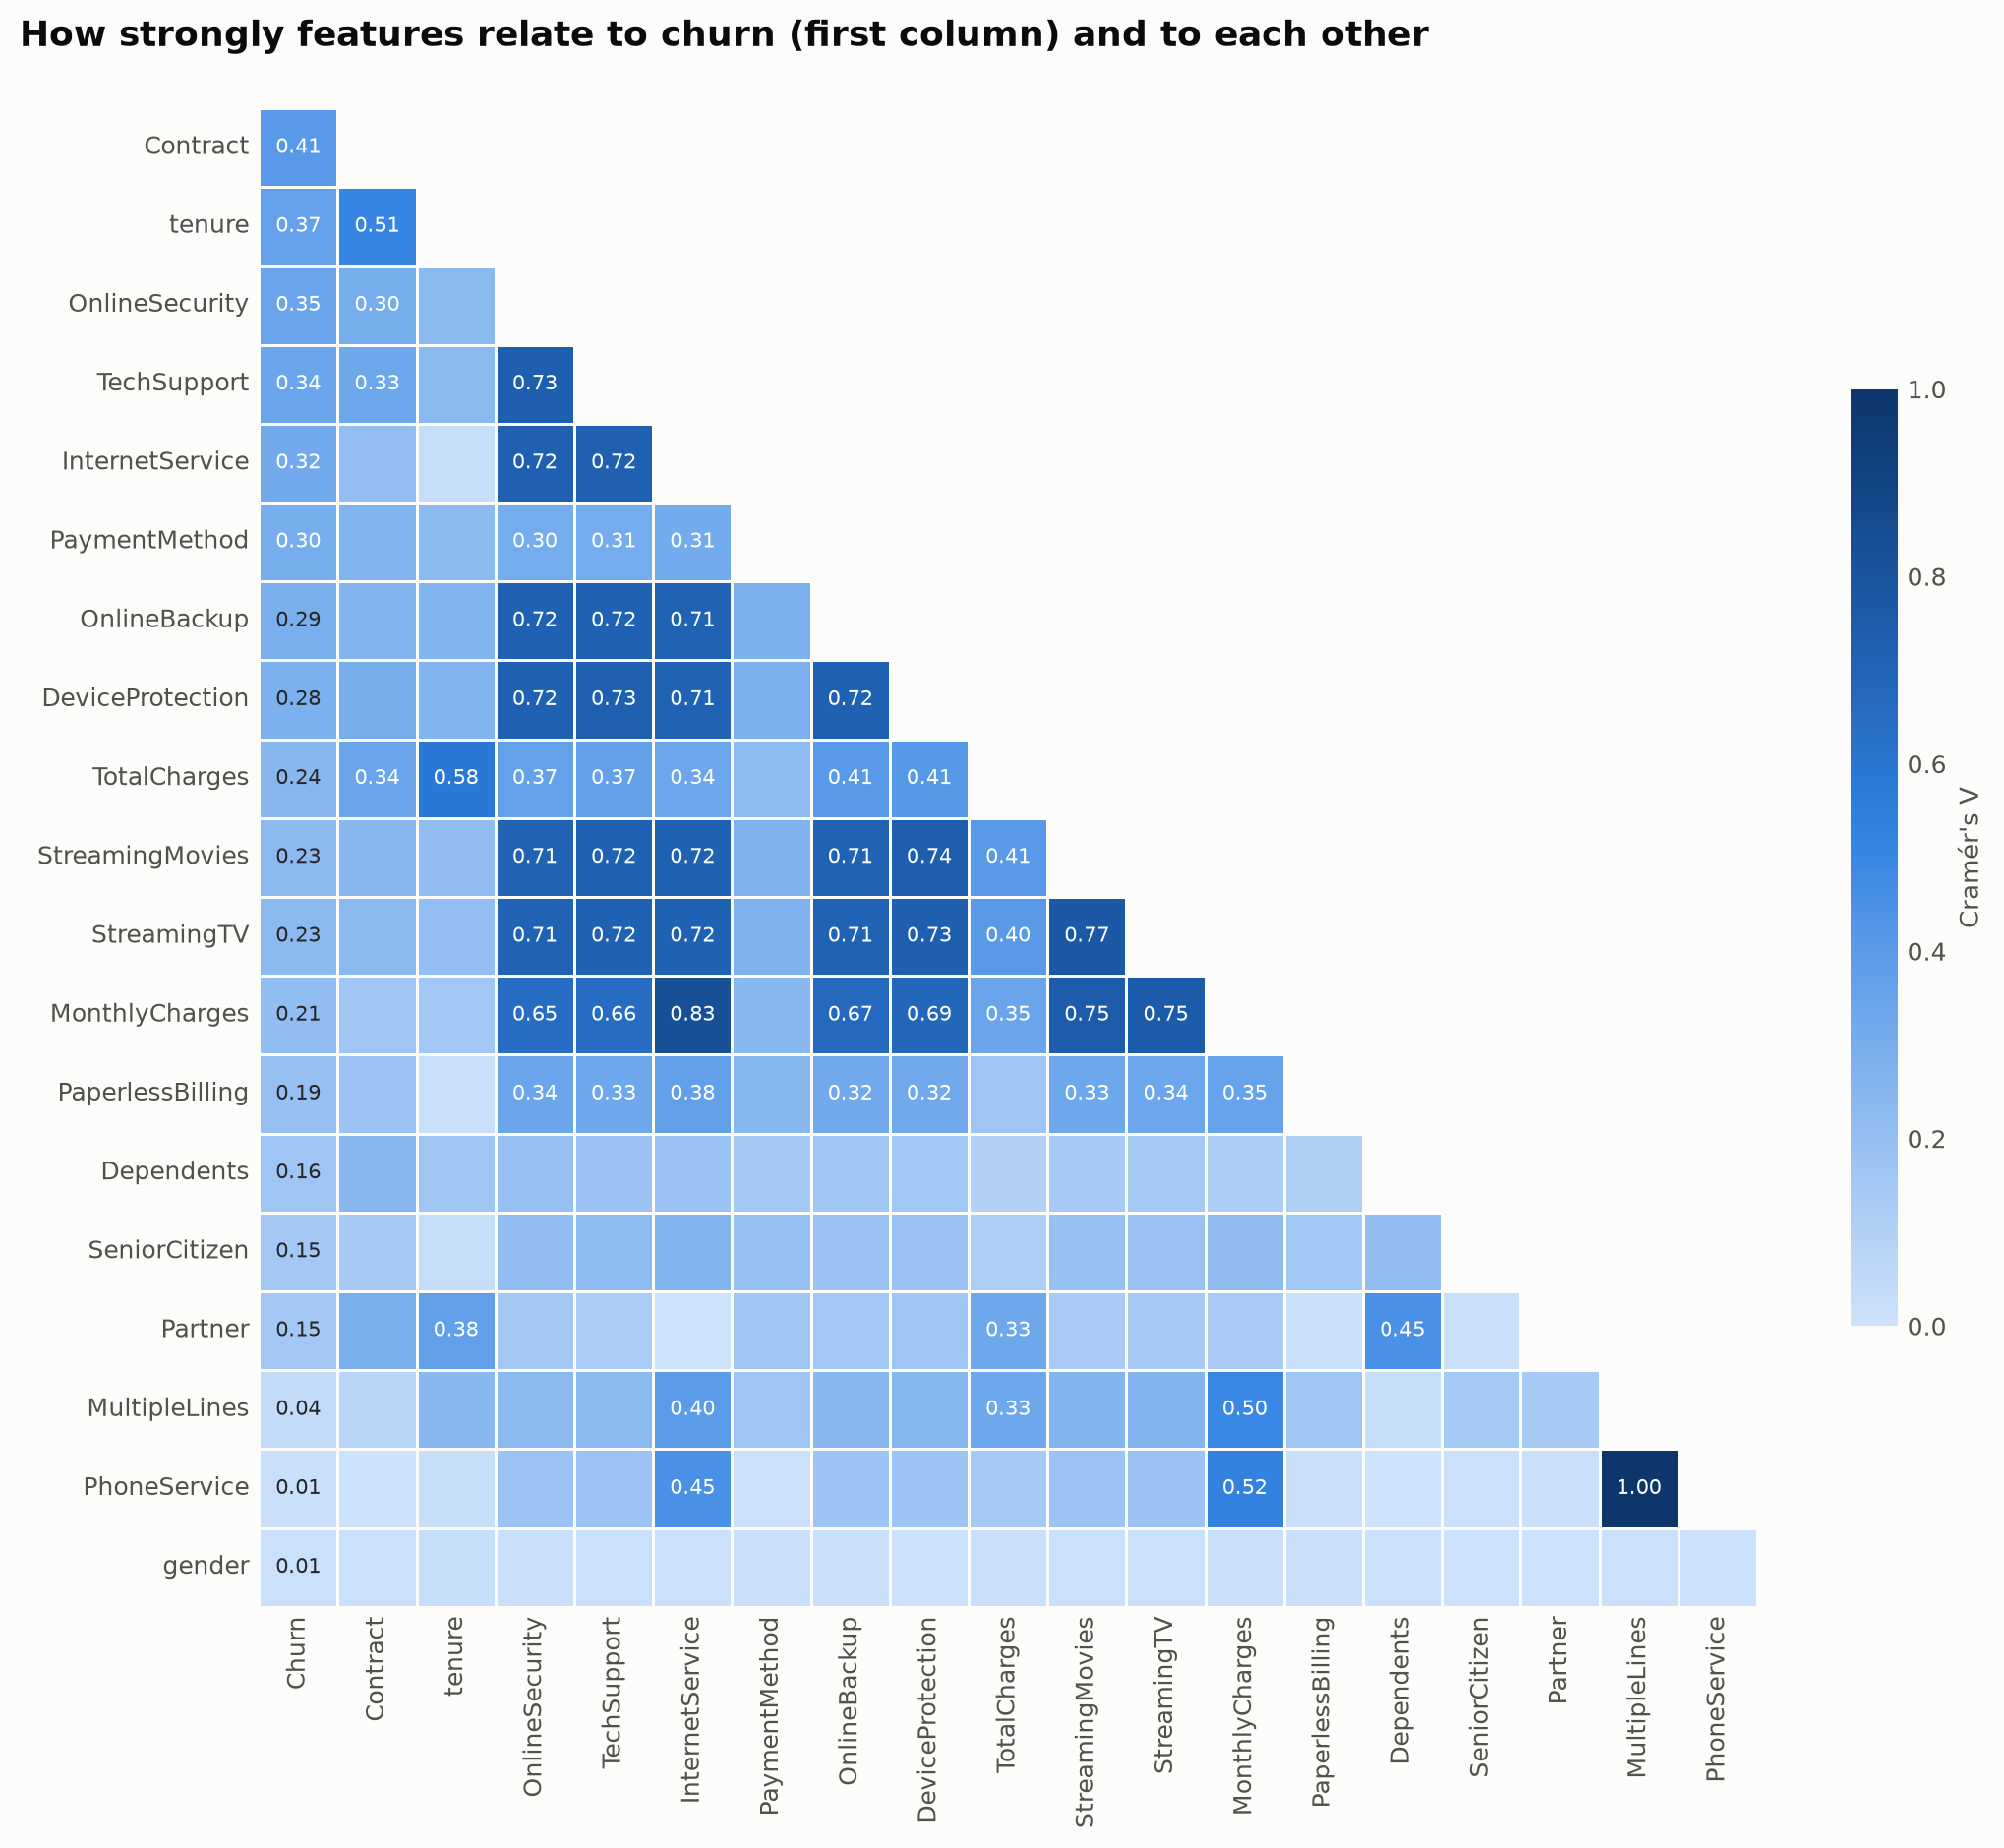

In [13]:
plot_association_matrix(
    association_matrix(df),
    "How strongly features relate to churn (first column) and to each other",
);

- Add-ons ↔ `InternetService` (≈ 0.72) and `MultipleLines` ↔ `PhoneService` (1.00) are inflated by the shared "No internet service" / "No phone service" levels; these are collapsed into "No" in preprocessing (section 3).
- `MonthlyCharges` is largely determined by the services (↔ `InternetService` 0.83), `TotalCharges` by tenure (0.58).
- Correlated inputs do not hurt prediction, but they share importance between features when the model is interpreted (section 8).

### Key findings

- **Imbalanced target** (26.5 % churn) → imbalance-aware metrics and a tuned decision threshold.
- **Biggest risk drivers:** month-to-month contract, short tenure, high monthly charges / fiber optic, no security or support add-ons, electronic check payment.
- **Interactions:** new customers with high bills churn the most (up to 77 %); contract length matters at every tenure.
- **Little or no signal:** gender, phone service, multiple lines, streaming.
- **For feature engineering:** count of add-ons, tenure groups, average vs current monthly charge; collapse the redundant "No … service" levels.

## 3. Feature engineering & preprocessing

First, 20 % of the customers are set aside as the **test set**, stratified so that both parts keep the 26.5 % churn rate. It is scored only once, in the final evaluation (section 7); everything until then, incl. the statistics below, uses the training set only.

In [14]:
X, y = split_features_target(df)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=config.RANDOM_STATE
)
print(f"Train: {len(X_train):,} customers, {y_train.mean():.1%} churn")
print(f"Test:  {len(X_test):,} customers, {y_test.mean():.1%} churn")

Train: 5,634 customers, 26.5% churn
Test:  1,409 customers, 26.5% churn


All preprocessing is part of one scikit-learn `Pipeline` (`churn.pipeline.build_pipeline`). In cross-validation every step is therefore fitted on the training folds only (no leakage), and the saved model accepts raw customer records:

1. **`FeatureEngineer`** (`churn.features`): stateless, learns nothing from the data. It re-applies `clean()`, merges the "No internet service" / "No phone service" levels into "No" (already encoded in `InternetService` / `PhoneService`) and adds four features:
   - `AvgMonthlyCharges` = `TotalCharges` / `tenure`: the average bill so far (new customers: the current bill)
   - `AbsChargeDelta` = |`MonthlyCharges` − `AvgMonthlyCharges`|: how far the current bill is from that average, i.e. a price or plan change
   - `NumAddons`: number of internet add-ons (0–6)
   - `TenureGroup`: 0–6, 7–12, 13–24, 25–48, 49+ months
2. **`ColumnTransformer`**: scales the numeric features and one-hot encodes the categorical ones (below).
3. **Model** (section 4).

In [15]:
features = FeatureEngineer().fit_transform(X_train)
new_columns = config.NEW_NUMERIC_COLUMNS + config.NEW_CATEGORICAL_COLUMNS
features[config.NUMERIC_COLUMNS + new_columns].head().round(2)

,tenure,MonthlyCharges,TotalCharges,AvgMonthlyCharges,AbsChargeDelta,NumAddons,TenureGroup
3738,35,49.20,1701.65,48.62,0.58,3,25–48
3151,15,75.10,1151.55,76.77,1.67,1,13–24
4860,13,40.55,590.35,45.41,4.86,3,13–24
3867,26,73.50,1905.70,73.30,0.20,4,25–48
3810,1,44.55,44.55,44.55,0.00,0,0–6


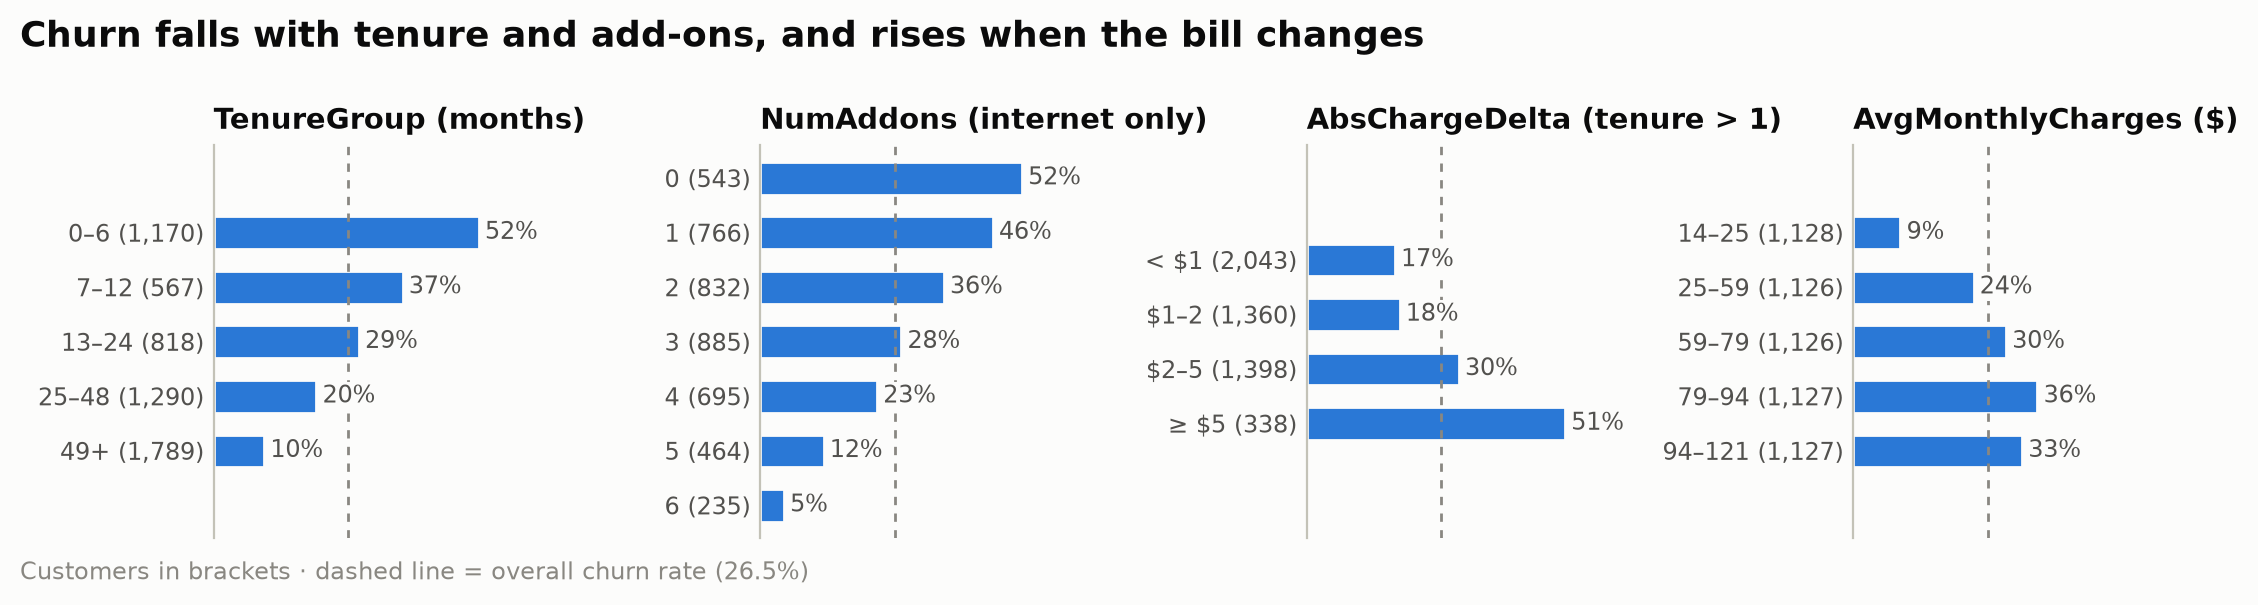

In [16]:
plot_new_features(
    features, y_train, "Churn falls with tenure and add-ons, and rises when the bill changes"
);

- **`TenureGroup`:** 52 % churn in the first 6 months, 10 % after 4 years; the groups let linear models follow the steep early drop.
- **`NumAddons`:** every add-on lowers churn, from 52 % (none) to 5 % (all six). Customers without internet have no add-ons but churn only 7 %; `InternetService` tells them apart.
- **`AbsChargeDelta`:** customers whose bill is ≥ USD 5 away from their average churn 51 %, vs 17 % below USD 1. Increases and decreases are equally risky (34 % each vs 18 % within ± USD 2), hence the absolute value. The panel leaves out tenure ≤ 1, where there is no history yet (delta 0).
- **`AvgMonthlyCharges`** is nearly identical to `MonthlyCharges` (Pearson correlation r = 0.996; 1 = perfectly linear), because `TotalCharges` ≈ `tenure` × `MonthlyCharges` (r = 0.9996). It adds little on its own, but `AbsChargeDelta` is derived from it.

**Scaling:** linear models, SVMs and neural networks need numeric inputs on comparable scales; tree models are unaffected. The **Yeo-Johnson** power transform, roughly (x + 1)^λ, first reduces skew, then standardises to mean 0 and standard deviation 1. It learns one exponent λ per feature from the training data (λ = 1: unchanged, λ = 0: log(1 + x), λ < 0: stronger than a log) and, unlike Box-Cox, works with zeros such as new customers' `TotalCharges`. The common manual alternative, **log1p** = log(1 + x), is a fixed transform: Yeo-Johnson with λ = 0 for every feature. Standardisation alone leaves the skew unchanged (`skew_raw` below).

In [17]:
compare_skewness(features[config.NUMERIC_COLUMNS + config.NEW_NUMERIC_COLUMNS]).round(2)

,skew_raw,skew_log1p,skew_yeo_johnson,lambda
tenure,0.24,-0.79,-0.24,0.45
MonthlyCharges,-0.22,-0.72,-0.26,0.93
TotalCharges,0.95,-0.82,-0.15,0.26
AvgMonthlyCharges,-0.21,-0.73,-0.26,0.92
AbsChargeDelta,2.49,0.50,0.07,-0.39
NumAddons,0.44,-0.19,-0.07,0.21


Yeo-Johnson brings every numeric feature close to symmetric (|skew| ≤ 0.26), incl. the most skewed ones, `TotalCharges` (0.95 → −0.15) and `AbsChargeDelta` (2.49 → 0.07). The fitted λ shows why one fixed log1p can't do this: `MonthlyCharges` needs almost no change (λ = 0.93), so log1p over-corrects it (−0.72), while `AbsChargeDelta` needs more than a log (λ = −0.39), so log1p under-corrects it (0.50).

**Encoding:** the categorical features have no order, so they are one-hot encoded: Yes/No features become a single 0/1 column, the others one column per level. Categories never seen in training are encoded as all zeros instead of crashing the service.

In [18]:
prepared = build_preprocessor().fit_transform(features)
print(f"{prepared.shape[1]} model inputs:", ", ".join(prepared.columns))

34 model inputs: tenure, MonthlyCharges, TotalCharges, AvgMonthlyCharges, AbsChargeDelta, NumAddons, gender_Male, SeniorCitizen_Yes, Partner_Yes, Dependents_Yes, PhoneService_Yes, MultipleLines_Yes, InternetService_DSL, InternetService_Fiber optic, InternetService_No, OnlineSecurity_Yes, OnlineBackup_Yes, DeviceProtection_Yes, TechSupport_Yes, StreamingTV_Yes, StreamingMovies_Yes, Contract_Month-to-month, Contract_One year, Contract_Two year, PaperlessBilling_Yes, PaymentMethod_Bank transfer (automatic), PaymentMethod_Credit card (automatic), PaymentMethod_Electronic check, PaymentMethod_Mailed check, TenureGroup_0–6, TenureGroup_13–24, TenureGroup_25–48, TenureGroup_49+, TenureGroup_7–12


The 19 raw features become 34 model inputs: 6 scaled numeric and 28 one-hot columns. Without the merged levels there would be 14 more (each merged feature: 3 columns → 1). Section 6 measures what each preprocessing step contributes to the results.

## 4. Model training & tuning

### 4.1 Metrics

A model gives every customer a churn probability; customers above a **decision threshold** are flagged and receive a retention offer. With churn as the positive class, the four possible outcomes have a business meaning:

| | Flagged (offer sent) | Not flagged |
|---|---|---|
| **Churns** | **TP:** churner reached in time to be won back | **FN:** churner missed → lost revenue |
| **Stays** | **FP:** offer wasted on a loyal customer → cost | **TN:** correctly left alone |

**Metrics** used in this notebook:

| Metric | Definition | Business meaning | No skill |
|---|---|---|---:|
| **PR-AUC** (primary) | average precision over all thresholds | how well the ranking puts churners first; focuses on the churn class | 0.265 |
| ROC-AUC | probability that a random churner is ranked above a random loyal customer | overall ranking quality; flattered by the many easy loyal customers | 0.5 |
| Brier score | mean squared error of the probabilities (lower = better) | can a "63 % risk" in the CRM be taken at face value? | 0.195 |
| Precision | TP / (TP + FP) | share of offers that reach actual churners → budget efficiency | 0.265 |
| Recall | TP / (TP + FN) | share of churners reached → revenue protected | share flagged |
| F1, F2 | harmonic mean of precision and recall; F2 weights recall 2× | one number per threshold; F2 because a missed churner costs more than a wasted offer | 0.42, 0.64 |
| Balanced accuracy | mean of the recall on churners and on loyal customers | accuracy that the imbalance can't inflate | 0.5 |
| Accuracy | (TP + TN) / all customers | misleading here: "no churn" for everyone already scores 73.5 % | 0.735 |

*No skill:* the churn rate as everyone's probability (PR-AUC, ROC-AUC, Brier), offers to everyone (precision, F1, F2) or to no one (accuracy). Models are tuned and compared on the threshold-free **PR-AUC**; the threshold is chosen afterwards to maximise F2 (section 7).

**Why not recall?** It cannot rank models: offers to everyone already give 100 % recall (with 73.5 % of them wasted on loyal customers), and any model reaches any recall by lowering its threshold. PR-AUC averages the precision over all recall levels, so a higher PR-AUC means fewer wasted offers across the recall levels one might target; recall gets its priority when the threshold is set (F2).

### 4.2 Candidate models and tuning

| Model | Approach | Why it is a candidate |
|---|---|---|
| Dummy (prior) | baseline | predicts the churn rate for everyone: the no-skill reference |
| Logistic regression | linear | interpretable (odds ratios) and well calibrated; strong when the features are good |
| Random forest | bagged trees | non-linear effects and interactions; robust with little tuning |
| XGBoost | boosted trees | usually the most accurate on tabular data |
| SVM (RBF kernel) | kernel method | smooth non-linear decision boundary |
| MLP | neural network | small feed-forward network: does a neural net add anything on 7k rows? |

Each model runs inside the full pipeline from section 3 and is tuned with `RandomizedSearchCV`: 25 random settings from its search space (`churn.models.candidates`), each scored by stratified 5-fold cross-validation on the training set, with the same folds for every model. Choosing settings by their score on held-out folds, not on the data they were fitted to, is what prevents overfitting: a complex setting only wins if it generalises. This takes about 2 minutes on 12 CPU cores.

In [19]:
searches = tune_models(X_train, y_train)
tuning = tuning_results(searches)
tuning.style.format(precision=3)

,pr_auc,pr_auc_std,roc_auc,worst_setting,fit_seconds,best_params
Logistic regression,0.671,0.017,0.850,0.659,0.349,C=0.191
XGBoost,0.666,0.020,0.849,0.604,1.147,"colsample_bytree=0.561, learning_rate=0.0336, max_depth=2, min_child_weight=1, n_estimators=476, reg_lambda=1.97, subsample=0.6"
MLP,0.664,0.021,0.847,0.592,1.458,"alpha=0.0785, hidden_layer_sizes=(64,), learning_rate_init=0.000817"
SVM (RBF),0.663,0.014,0.843,0.495,2.127,"C=5.99, gamma=0.00138"
Random forest,0.663,0.022,0.848,0.637,2.666,"max_depth=12, max_features=sqrt, min_samples_leaf=15, n_estimators=306"
Dummy (prior),0.265,0.000,0.500,0.265,0.227,


- **All models are close:** PR-AUC 0.66–0.67 (no skill: 0.265) and ROC-AUC ≈ 0.85. The gaps (≤ 0.008) are far smaller than the fold-to-fold standard deviation (≈ 0.02), and the scores are slightly optimistic, as the same folds chose the settings; section 5 re-scores all models on fresh folds.
- **Simple wins:** the best settings of the flexible models lie at the regularised end of their search spaces: depth-2 trees for XGBoost, leaves of ≥ 15 customers for the random forest, a nearly linear kernel for the SVM (small `gamma`) and a strong penalty for the MLP. The churn signal is mostly additive, so logistic regression keeps up.
- **Tuning matters for flexible models:** the worst sampled setting loses 0.17 PR-AUC for the SVM, 0.07 for the MLP and 0.06 for XGBoost, but only 0.01 for logistic regression.

### 4.3 Ensemble

`best_models` collects every model with its best setting for the comparison in section 5. The SVM only outputs scores; Platt scaling (a logistic fit on cross-validated scores) turns them into probabilities. The **ensemble** averages the predicted probabilities of the three best models (soft voting): models that make different errors partly cancel each other out.

In [20]:
models = best_models(searches)
print("Ensemble:", " + ".join(name for name, _ in models["Ensemble"].estimators))

Ensemble: Logistic regression + XGBoost + MLP


## 5. Model comparison & selection

The tuning scores in section 4.2 are slightly optimistic, as the same folds that chose each model's setting also scored it. All tuned models and the ensemble are therefore re-scored on **fresh folds**: stratified 5-fold cross-validation on the training set, repeated 3 times with new shuffles, i.e. 15 scores per model. Every model is scored on the same 15 folds, so the models can also be compared fold by fold. This takes about 20 seconds on 12 CPU cores.

In [21]:
scores = cross_validate_models(models, X_train, y_train)
comparison = comparison_table(scores, searches)
comparison.style.format(precision=3, na_rep="–")

,pr_auc,pr_auc_std,tuning_pr_auc,roc_auc,brier,fit_seconds
model,,,,,,
Logistic regression,0.672,0.020,0.671,0.850,0.133,0.490
Ensemble,0.670,0.020,–,0.849,0.133,2.355
XGBoost,0.666,0.018,0.666,0.849,0.134,0.834
SVM (RBF),0.664,0.020,0.663,0.843,0.136,6.145
Random forest,0.662,0.018,0.663,0.846,0.135,2.120
MLP,0.657,0.027,0.664,0.842,0.136,1.099
Dummy (prior),0.265,0.000,0.265,0.500,0.195,0.404


- **Same ranking as in tuning:** logistic regression again has the best mean PR-AUC (0.672), ahead of the ensemble (0.670) and XGBoost (0.666); every model reaches ≈ 2.5× the no-skill 0.265. The gaps (≤ 0.015) are still smaller than the fold-to-fold spread (std ≈ 0.02).
- **Tuning optimism is small:** four models score within 0.001 of their tuning score (`tuning_pr_auc`). Only the MLP loses noticeably (0.664 → 0.657): its tuning score was partly luck of the folds, and it varies most between folds (std 0.027).
- **Probabilities:** Brier score 0.133–0.136 for every model vs 0.195 without skill; logistic regression and the ensemble are the most accurate.

**Selection rule** (`churn.evaluation.select_model`): the best mean PR-AUC wins, but a simpler model is preferred if its mean is within one standard deviation of the best. Simpler means easier to explain, better calibrated and cheaper to serve: logistic regression < XGBoost < random forest < SVM < MLP < ensemble.

Final model: Logistic regression


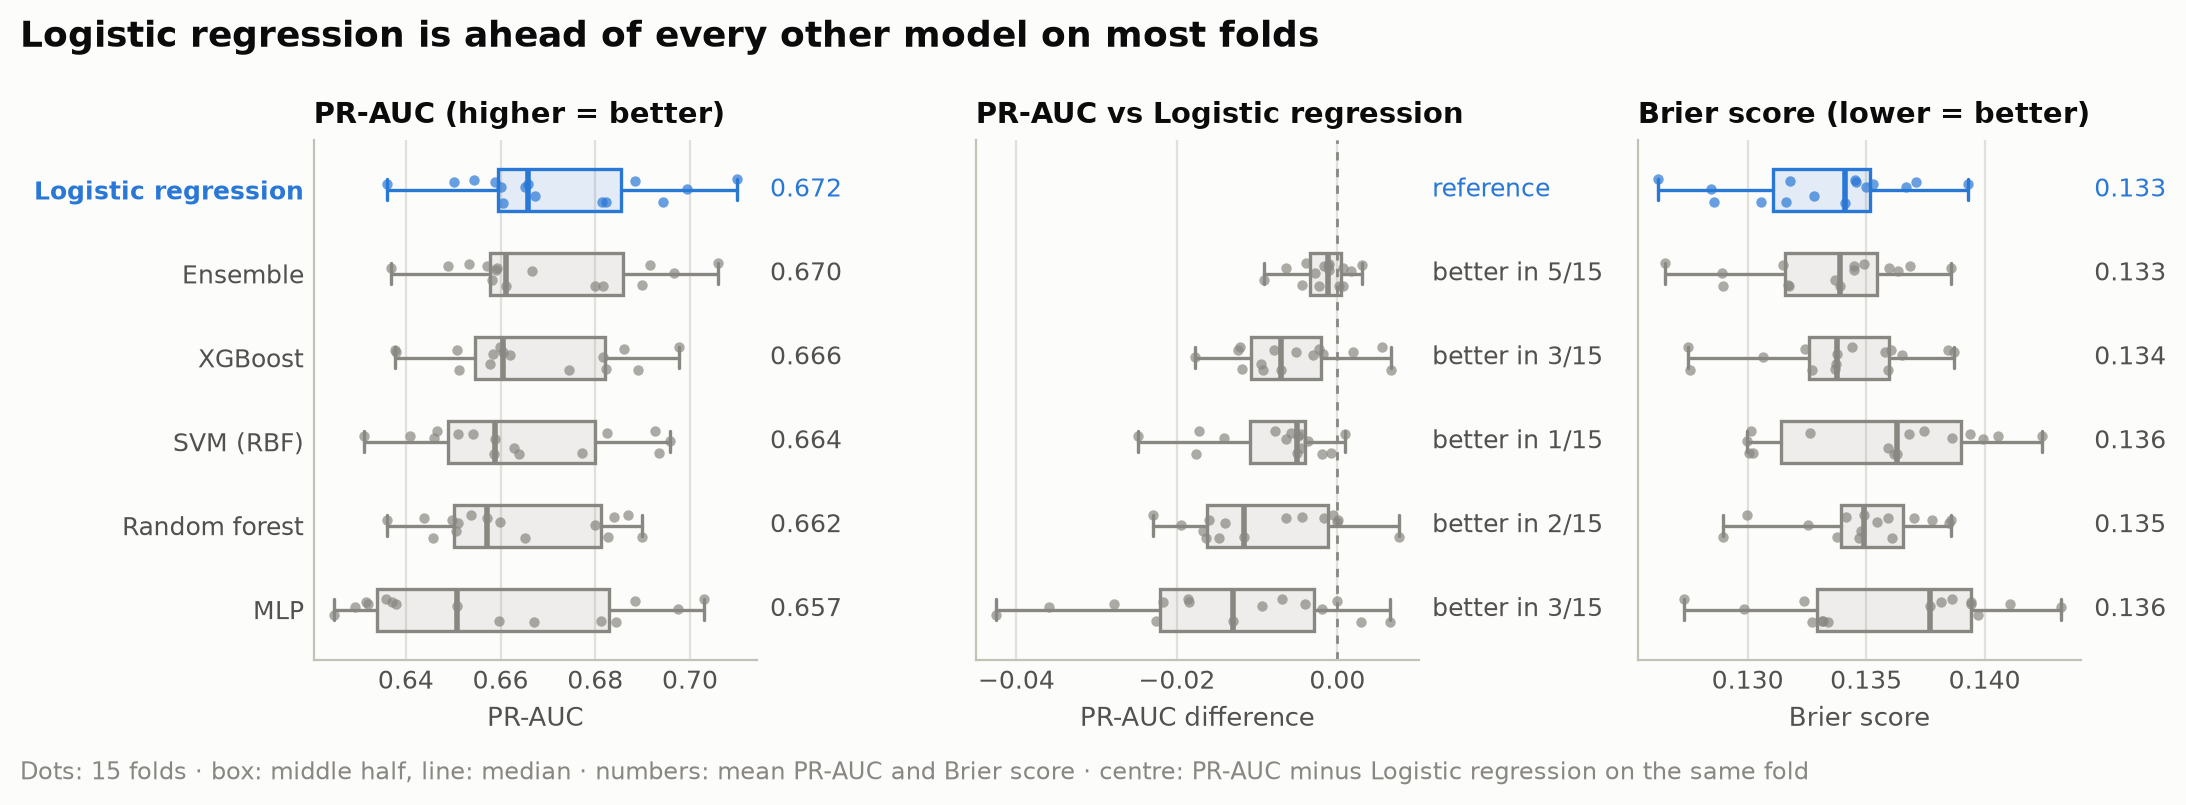

In [22]:
final_name = select_model(comparison)
final_model = models[final_name]
print("Final model:", final_name)
plot_model_comparison(
    scores, final_name, "Logistic regression is ahead of every other model on most folds"
);

**Final model: logistic regression.** It has the best mean PR-AUC, so the rule needs no tie-break, and it is also the simplest candidate.

- **Raw scores (left):** the boxes overlap almost completely, because some folds are harder than others for every model.
- **Same fold (centre):** subtracting logistic regression's score on the same fold removes that shared difficulty. The differences vary much less (std 0.003–0.014 instead of ≈ 0.02) and are mostly negative: logistic regression is ahead of the SVM on 14 of the 15 folds, the random forest on 13, XGBoost and the MLP on 12 and the ensemble on 10. The ensemble ties at best: its non-linear members add nothing the linear model misses.
- **Probabilities (right):** logistic regression's probabilities are the most accurate as well (Brier 0.133, tied with the ensemble), so a churn risk shown in the CRM can be taken at face value.
- **Fit for the use case:** odds ratios explain each churn driver directly to marketing (section 8); it trains in under a second and is trivial to serve.

The churn signal in this data is mostly additive (contract, tenure, services, charges): the flexible models' best settings were their most regularised ones (section 4.2), and their extra flexibility only adds variance.

## 6. Effects of preprocessing (ablation)

What does each preprocessing step contribute? Starting from a minimal pipeline, the steps are added one at a time, and every variant is scored on the same 15 folds as in section 5:

| Variant | Adds |
|---|---|
| Baseline | the cleaned data, one-hot encoded; numbers unscaled |
| + standardisation | numbers rescaled to mean 0 and standard deviation 1 |
| + Yeo-Johnson | skew correction before standardising (replaces plain standardisation) |
| + level collapse | "No internet service" / "No phone service" → "No" |
| + new features | the four features from section 3: the final setup |
| + class weights | churners weighted ≈ 2.8× so that they count as much as all other customers together |

Three models take part: **logistic regression** (the final model), **XGBoost** (tree splits depend only on the order of the values, so scaling should change nothing: a control) and the **SVM** (its RBF kernel compares customers by distance, so it is the most sensitive to scale). Each keeps its tuned setting from section 4, so only the preprocessing changes; as those settings were tuned on the final setup, the comparison slightly favours it. This takes about 1.5 minutes on 12 CPU cores.

The table lists the mean PR-AUC and Brier score of each variant; the chart shows how much each step changes PR-AUC on the same fold (as in section 5).

In [23]:
ablation = run_ablation(models, X_train, y_train)
ablation_table(ablation).style.format(precision=3)

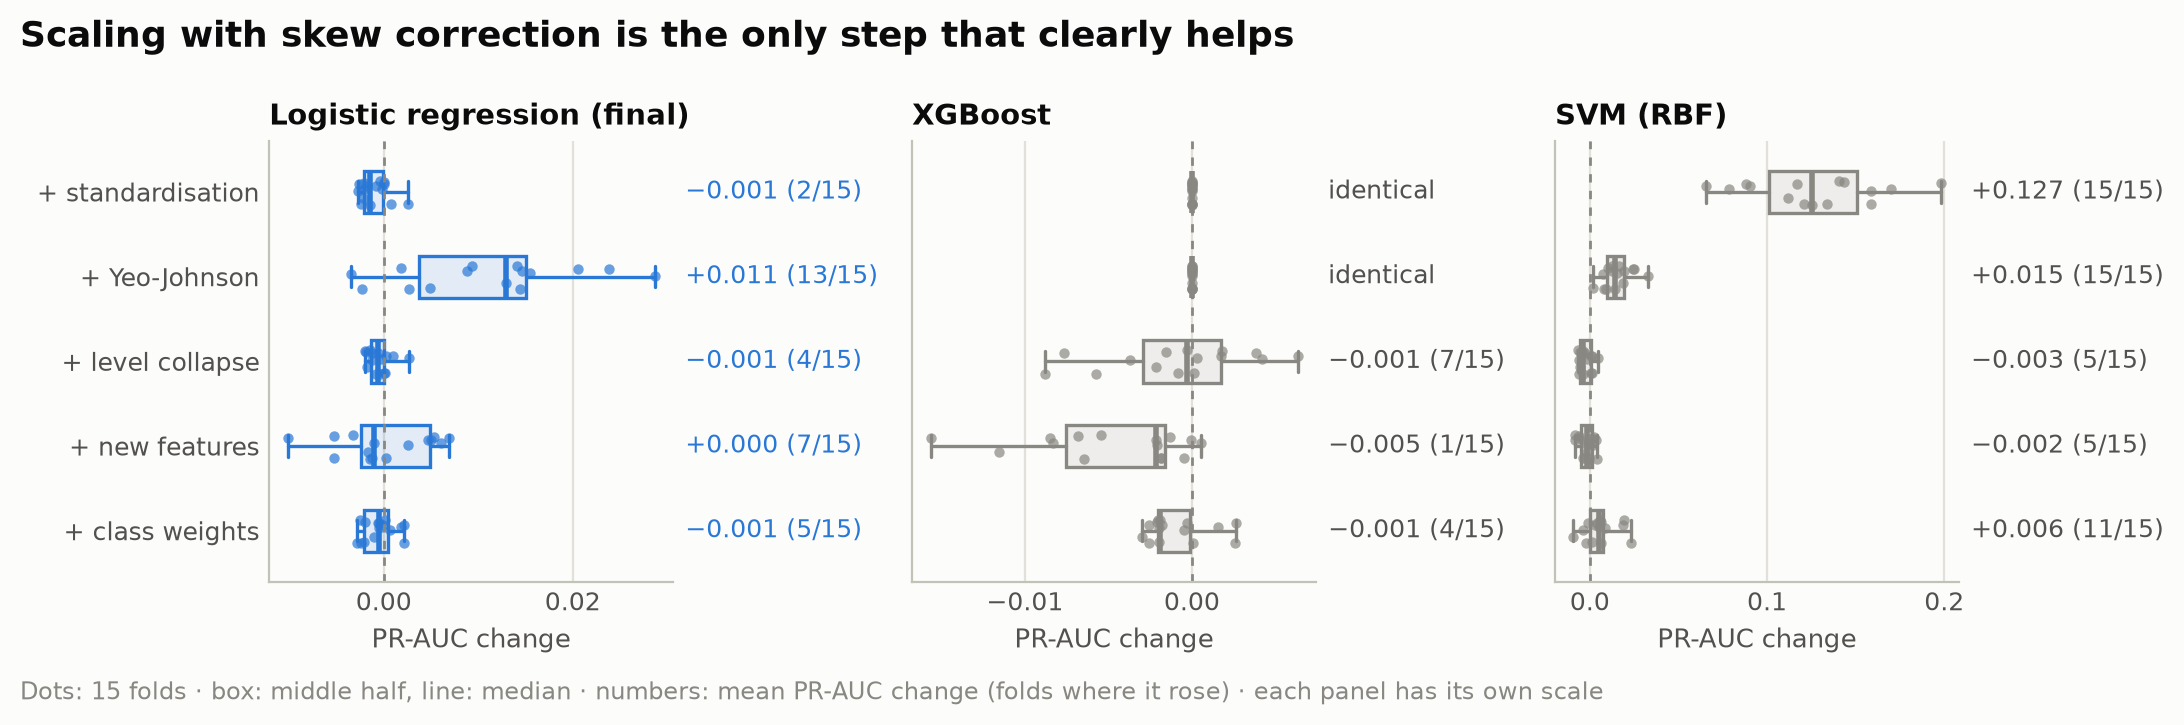

In [24]:
plot_ablation(
    step_effects(ablation),
    final_name,
    "Scaling with skew correction is the only step that clearly helps",
);

The final setup reproduces the scores of section 5 (same folds, same settings).

- **Scaling:** the SVM depends on it: PR-AUC 0.526 unscaled → 0.653 standardised → 0.668 with Yeo-Johnson, better on all 15 folds at both steps. Unscaled, its distances are dominated by `TotalCharges` (up to 8,685), so the other features barely count. Plain standardisation changes nothing for logistic regression (−0.001), but Yeo-Johnson adds +0.011 (13 of 15 folds): bending `tenure` and `TotalCharges` (λ = 0.45 and 0.26, section 3) lets a linear model follow the steep drop in churn over the first months. XGBoost is identical in all three, as expected.
- **Level collapse:** no effect on the ranking (−0.003 to −0.001); it stays because it removes 14 redundant inputs, which simplifies the explanations (section 8).
- **New features:** no gain (logistic regression +0.000, SVM −0.002, XGBoost −0.005, lower on 14 of 15 folds). Tenure, add-ons and bill changes are already in the raw columns once Yeo-Johnson has fixed the skew. The features stay in the pipeline, as they cost the final model nothing.
- **Class weights:** the ranking barely changes (−0.001 for logistic regression and XGBoost), but the probabilities get much worse: weighting churners up pushes every predicted risk upwards (Brier score 0.133 → 0.161 for logistic regression, 0.134 → 0.161 for XGBoost). The SVM's Platt scaling re-calibrates its weighted scores, so its Brier score does not suffer. The final model stays unweighted; the decision threshold handles the imbalance instead (section 7).

**Conclusion:** only scaling with skew correction (Yeo-Johnson) clearly improves the models that need scaling. Level collapse and the new features leave the accuracy unchanged, and class weights would only distort the probabilities.

## 7. Threshold tuning & final evaluation

The model gives every customer a churn probability; the **decision threshold** turns it into an offer or none. Section 7.1 chooses the threshold on the training set; sections 7.2–7.4 then score the final model on the test set, for the first and only time. Model, settings and threshold are fixed by then, so the test scores are an honest estimate for new customers.

### 7.1 Decision threshold

F2 weights recall twice as much as precision, as a missed churner usually costs more than a wasted offer (section 4.1). The threshold is chosen by cross-validation on the training set (scikit-learn's `TunedThresholdClassifierCV`): on each of the 15 folds of section 5, a model trained on the other folds scores the held-out customers, F2 is computed at the thresholds 0.01, 0.02, …, 0.99, and the threshold with the highest mean F2 wins. The model is then refitted on the full training set.

In [25]:
tuned = tune_threshold(final_model, X_train, y_train)
threshold = tuned.best_threshold_
low, high = near_optimal(tuned)
print(f"F2-optimal threshold: {threshold:.2f} (mean CV F2 {tuned.best_score_:.3f})")
print(f"Within 0.01 of that F2: thresholds {low:.2f}–{high:.2f}")
thresholds = {"0.50 (default)": 0.5, f"{threshold:.2f} (F2)": threshold}

F2-optimal threshold: 0.19 (mean CV F2 0.749)
Within 0.01 of that F2: thresholds 0.08–0.23


**Why so far below 0.5?** A threshold of 0.5 flags a customer only if churn is more likely than not, which is right if a missed churner and a wasted offer weigh the same. F2 does not weigh them the same: in its formula, 5·TP / (5·TP + 4·FN + FP), a missed churner (FN) counts four times as much as a wasted offer (FP). Offers therefore pay off already at a moderate risk: at 0.19, a customer gets one although about four in five customers with that risk would stay.

**How exact is 0.19?** Every threshold from 0.08 to 0.23 reaches a mean F2 within 0.01 of the best, so F2 hardly tells them apart. They do differ in how many customers get an offer (chart in section 7.3), so within this range the budget can decide.

### 7.2 Ranking and probabilities on the test set

All tuned models are refitted on the full training set and score the test customers. The choice of logistic regression (section 5) stays fixed; the other models only show whether the picture from cross-validation holds.

**Reading the tables:** `test` is the score on the test set, `cv_mean` the mean over the 15 CV folds of section 5. Other customers would give a slightly different test score; `ci_low`–`ci_high` shows how different. This **95 % interval** comes from a bootstrap: draw 1,409 customers from the test set at random, with replacement (some twice, some not at all), score them, and repeat 1,000 times; the middle 95 % of the 1,000 scores is the interval. A narrow interval means a precise score, and a CV mean inside it means that the test confirms cross-validation.

In [26]:
holdout = holdout_probabilities(models, X_train, y_train, X_test)
proba = holdout[final_name]
holdout_ranking(y_test, proba, scores[scores["model"] == final_name]).style.format(precision=3)

,cv_mean,test,ci_low,ci_high
pr_auc,0.672,0.670,0.618,0.717
roc_auc,0.850,0.847,0.825,0.868
brier,0.133,0.134,0.124,0.144


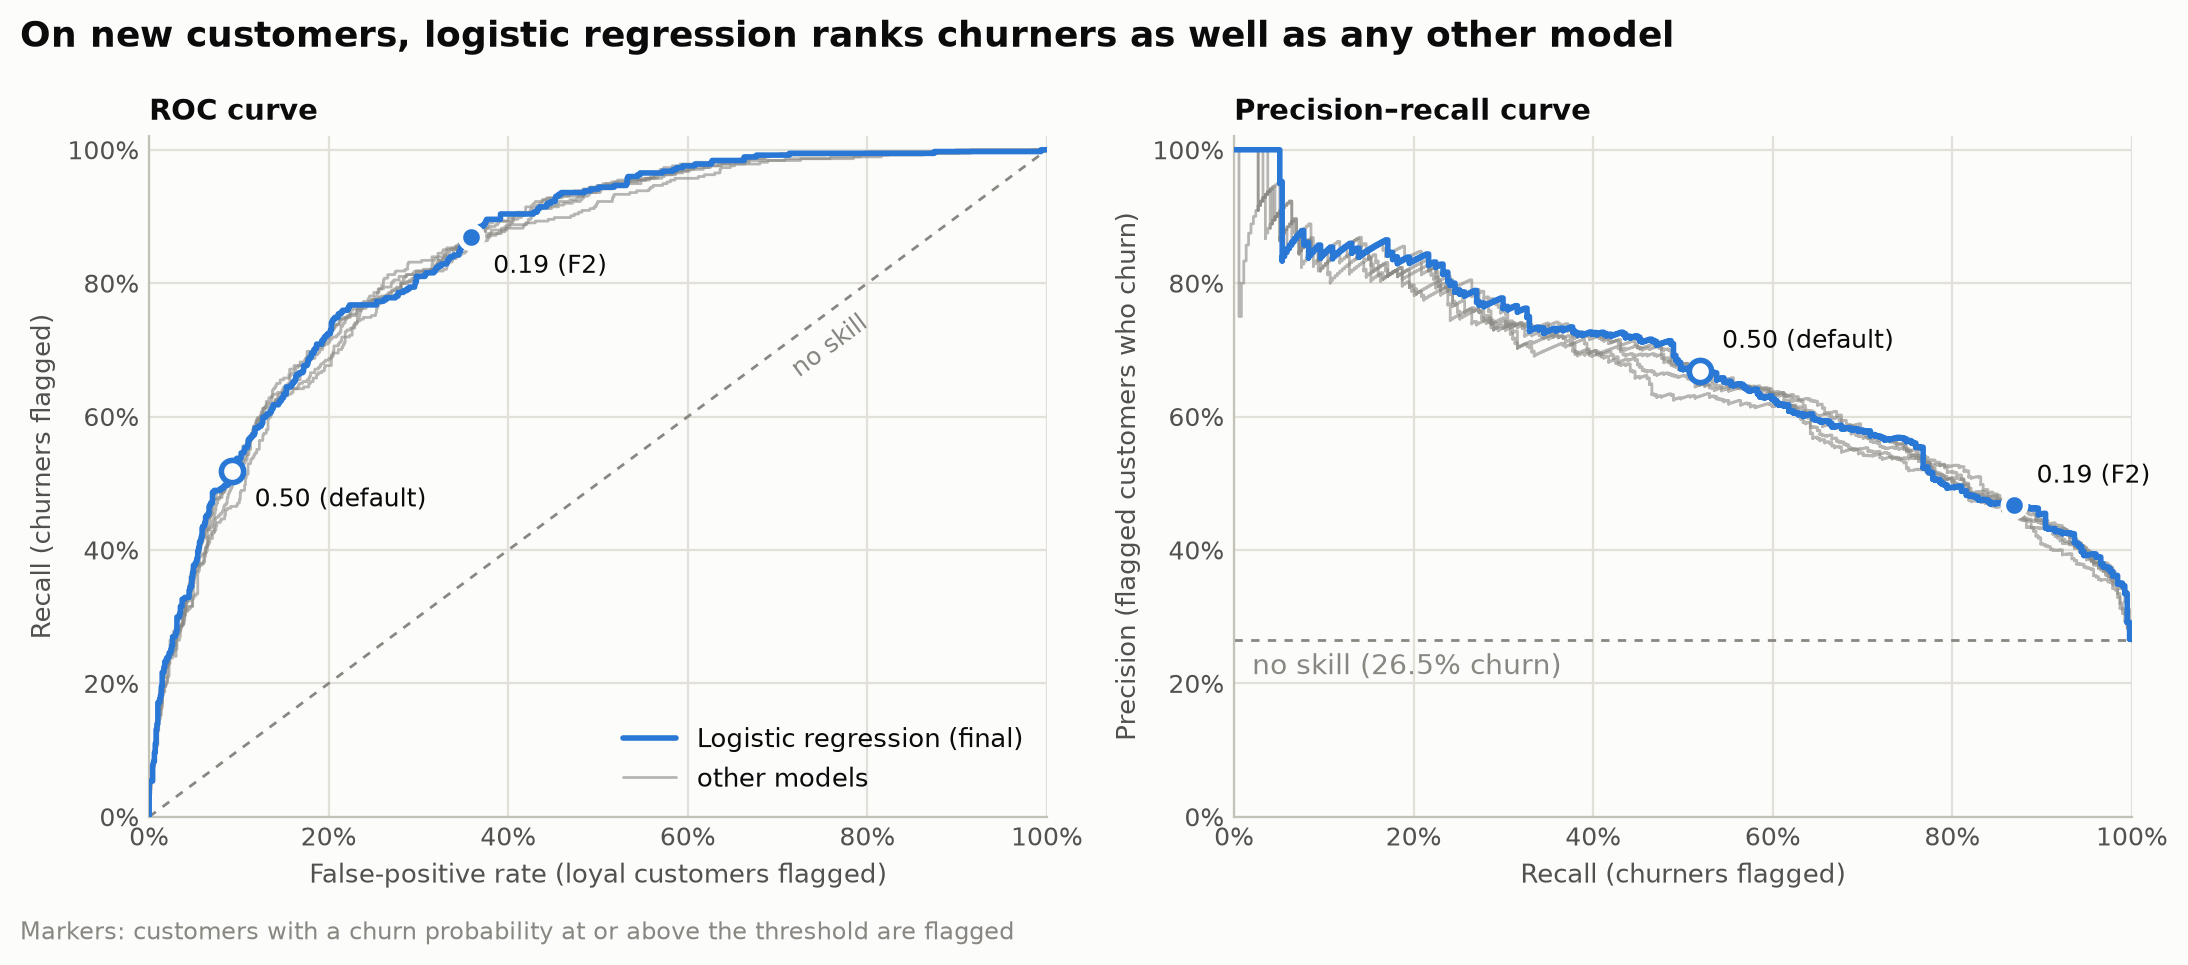

In [27]:
plot_holdout_curves(
    y_test,
    holdout,
    final_name,
    thresholds,
    "On new customers, logistic regression ranks churners as well as any other model",
);

**Reading the chart:** every point of a curve is one threshold. Lowering it flags more customers, so the curves run from the bottom left (no one flagged) to the top right (everyone flagged) in the ROC panel and from left to right in the precision–recall panel. The better a model ranks churners, the closer its curve stays to the top-left (ROC) or top-right (precision–recall) corner; the dashed lines are a random ranking, and the markers show where the thresholds 0.5 and 0.19 lie.

- **As in cross-validation:** PR-AUC 0.670 on the test set vs 0.672 (CV mean), ROC-AUC 0.847 vs 0.850, Brier score 0.134 vs 0.133. Every CV mean lies inside the test interval, so the cross-validated scores were not optimistic.
- **Uncertainty:** with 374 churners, the test PR-AUC alone is only known to about ±0.05 (0.618–0.717); the CV folds give the sharper estimate, the test set the independent check.
- **Other models:** their curves (gray) overlap with logistic regression's almost everywhere, as in section 5.

### 7.3 Decisions: what the threshold changes

The threshold metrics of section 4.1 at the default 0.5 and at the F2 threshold; `share_flagged` is the share of customers who get an offer.

In [28]:
holdout_decisions(y_test, proba, thresholds).style.format(precision=3)

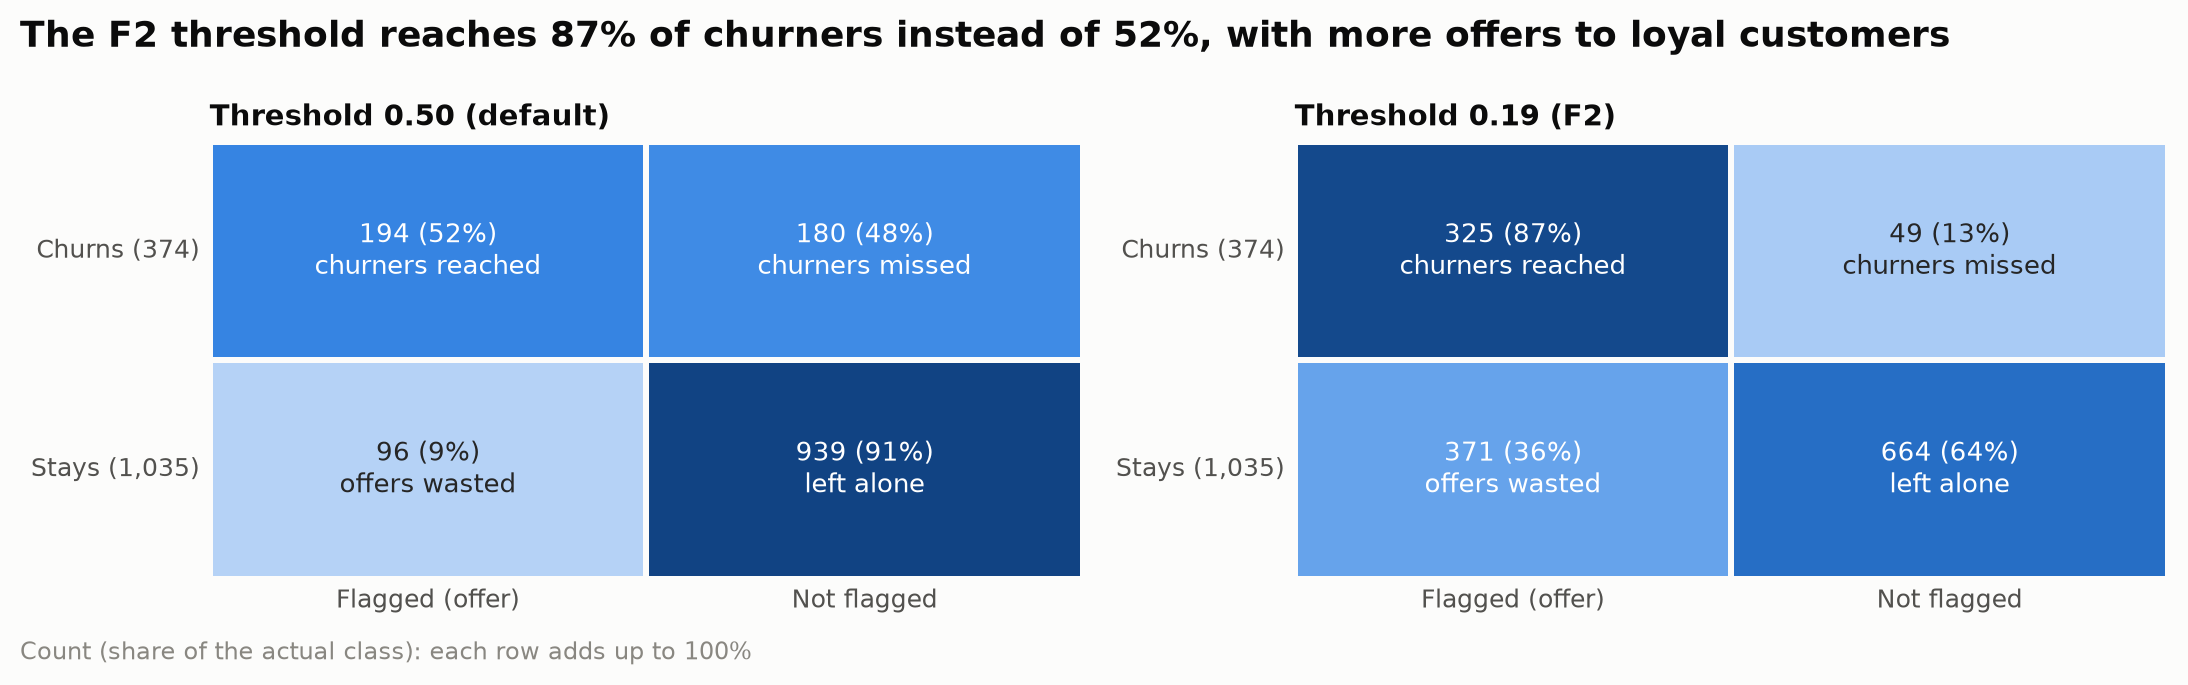

In [29]:
plot_confusion_matrices(
    y_test,
    proba,
    thresholds,
    "The F2 threshold reaches 87% of churners instead of 52%, with more offers to loyal customers",
);

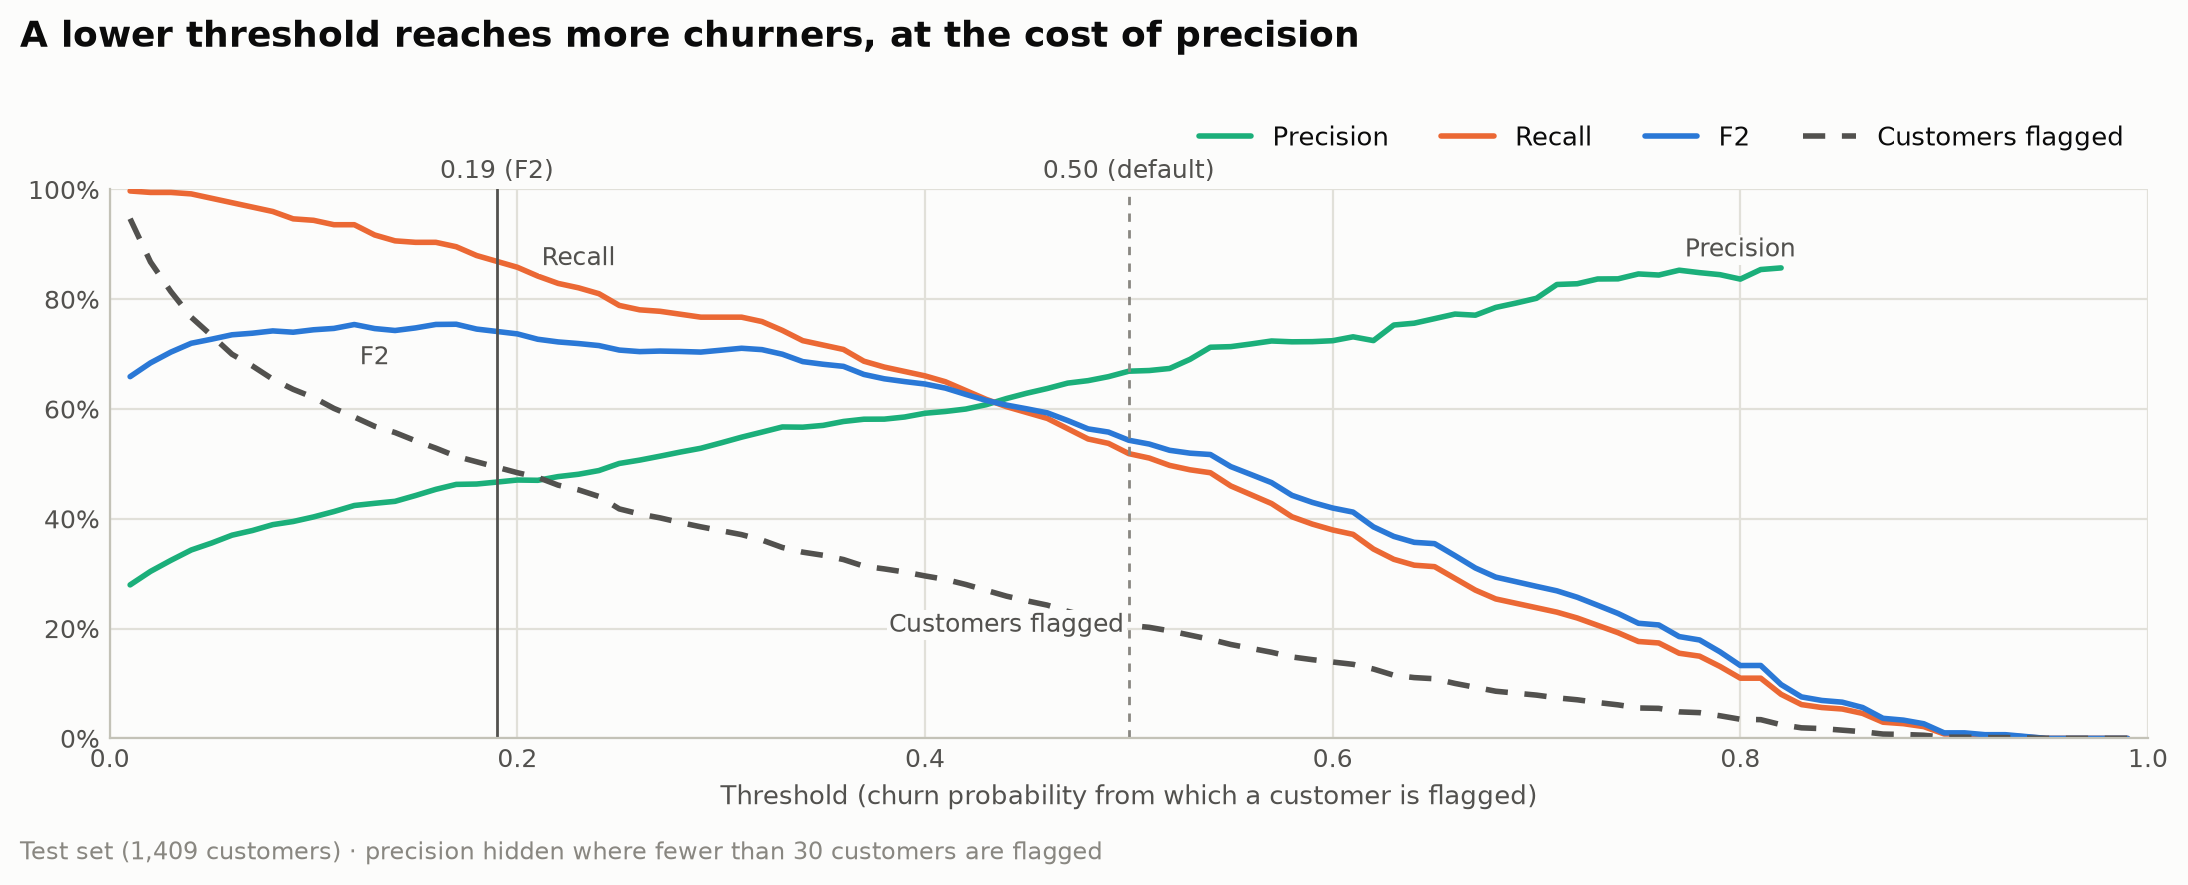

In [30]:
plot_threshold_metrics(
    metrics_by_threshold(y_test, proba),
    thresholds,
    len(y_test),
    "A lower threshold reaches more churners, at the cost of precision",
);

- **More churners reached:** the F2 threshold flags 49 % of the customers and reaches 325 of the 374 churners (87 %), against 194 (52 %) at 0.5.
- **At a price:** 371 loyal customers get an offer instead of 96, so 47 % of the offers reach a churner instead of 67 %. Whether that pays off depends on the cost of an offer and the value of a retained customer; the chart above shows the other operating points, e.g. for a smaller budget.
- **Accuracy drops** (0.804 → 0.702) while F2 and balanced accuracy rise: accuracy rewards leaving churners alone (section 4.1).
- **Robust:** on the test set, too, F2 peaks close to the chosen threshold.

### 7.4 Probability quality and targeting

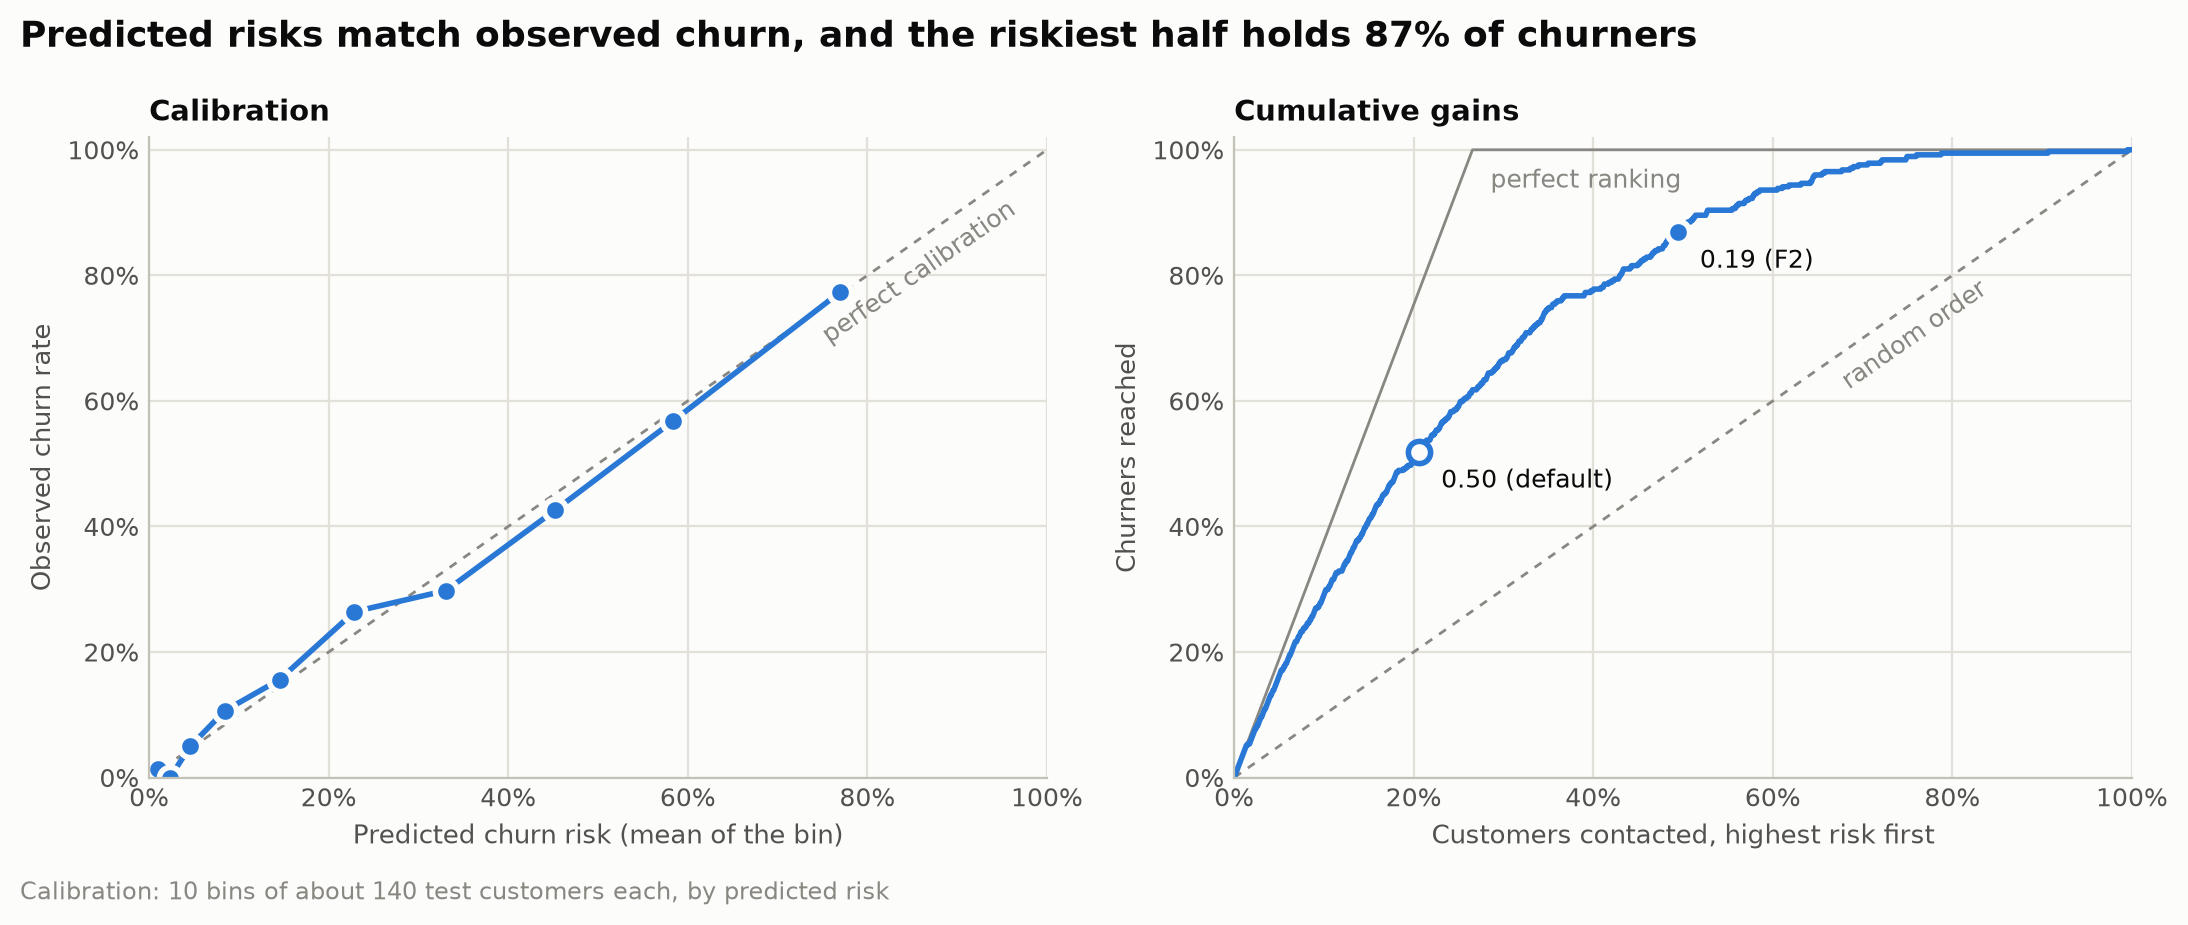

In [31]:
plot_calibration_and_gains(
    y_test,
    proba,
    thresholds,
    "Predicted risks match observed churn, and the riskiest half holds 87% of churners",
);

- **Calibration:** all 10 bins lie close to the diagonal, so a risk shown in the CRM can be taken at face value: of 10 customers with a 60 % risk, about 6 leave.
- **Targeting:** ranking customers by risk concentrates the churners: the riskiest 21 % hold 52 % of them (threshold 0.5), the riskiest 49 % hold 87 % (threshold 0.19), where a random 49 % would hold 49 %.

**Conclusion:** the final model holds up on new customers: its test scores match cross-validation and its probabilities are calibrated. With the F2 threshold, offers to half of the customers reach 87 % of those who would otherwise leave; a higher threshold trades churners reached for fewer offers.

## 8. Explainability

Why does the model flag a customer? For logistic regression, two views are exact:

- **SHAP values** split a customer's predicted log-odds into one contribution per feature: how far that feature moves the customer from an *average customer*, one with every input at its training mean. The contributions add up exactly to the prediction. (Log-odds = log(p / (1 − p)): 0 is a 50 % risk, and every +0.7 doubles the odds.)
- **Odds ratios** show how the odds of churning change with one input while all other inputs stay the same.

SHAP values are computed for the test customers, the odds ratios from the final model's coefficients.

### 8.1 What drives the churn risk

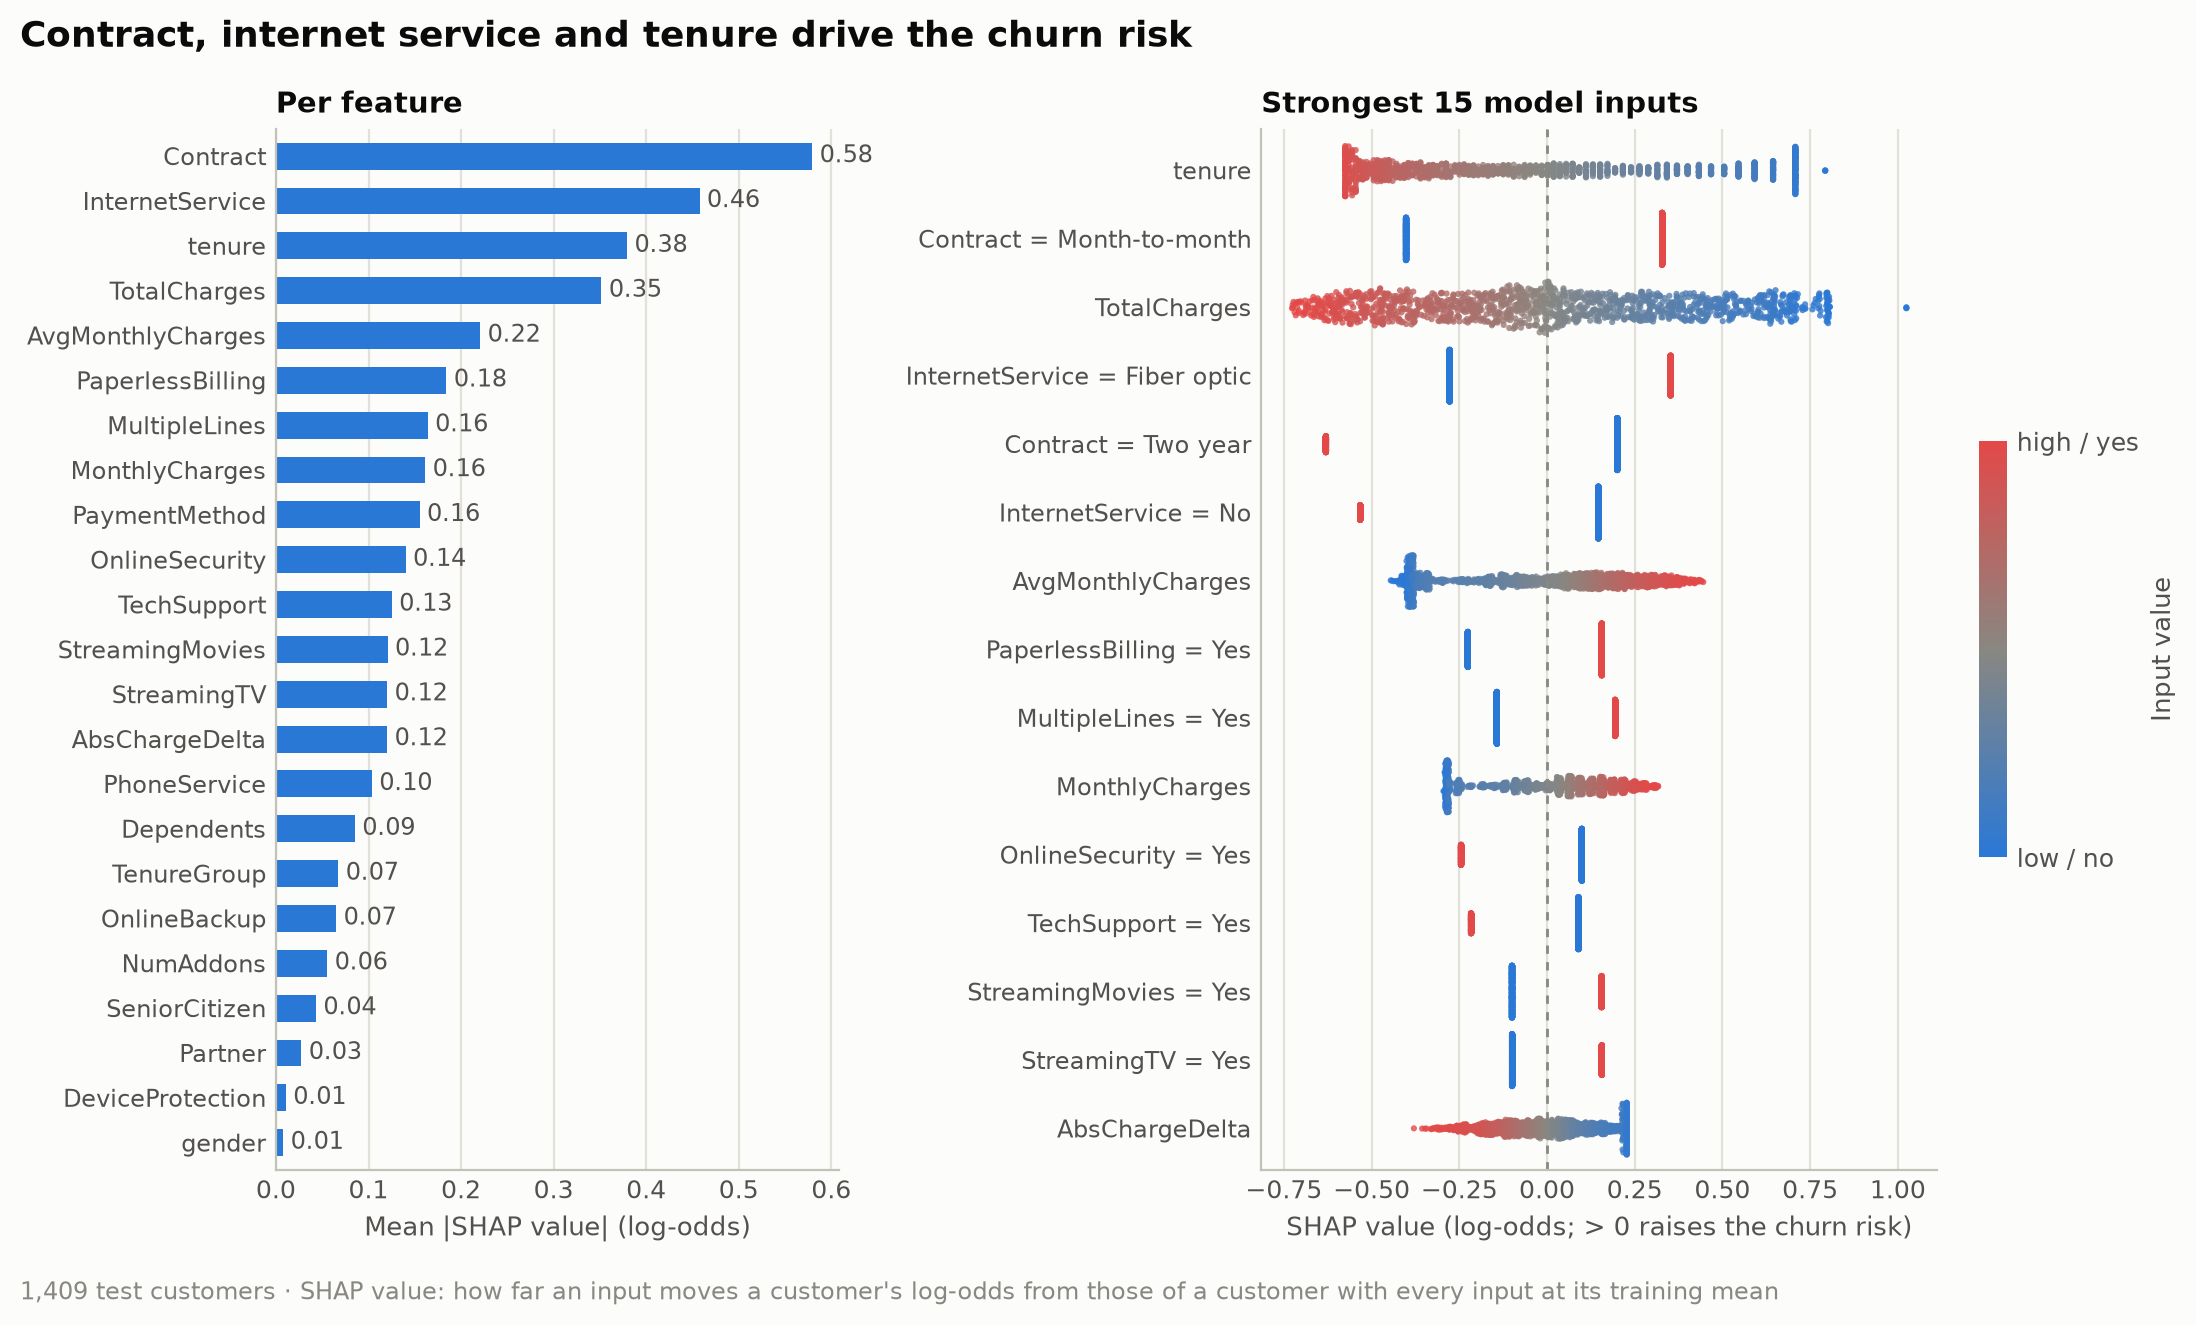

In [32]:
final_pipeline = tuned.estimator_  # logistic regression, refitted on all training data (7.1)
shap_values = explain(final_pipeline, X_train, X_test)
plot_shap_summary(shap_values, "Contract, internet service and tenure drive the churn risk");

- **Commitment and product first:** contract (0.58), internet service (0.46) and tenure (0.38) move the log-odds most. Month-to-month contracts and fiber optic raise the risk; two-year contracts, no internet service and a long tenure lower it.
- **Support services help:** online security and tech support lower the risk; paperless billing, multiple lines and streaming raise it.
- **Demographics barely matter:** gender (0.01), partner (0.03) and senior citizen (0.04) have the smallest effects, as in section 2.
- **A linear model:** the dots of each numeric input run from blue to red in strict order, as a contribution is proportional to the (transformed) input value.

### 8.2 Why one customer is flagged

The waterfall explains one test customer: the flagged churner with the median risk among all flagged churners, the kind of case marketing would see in the CRM.

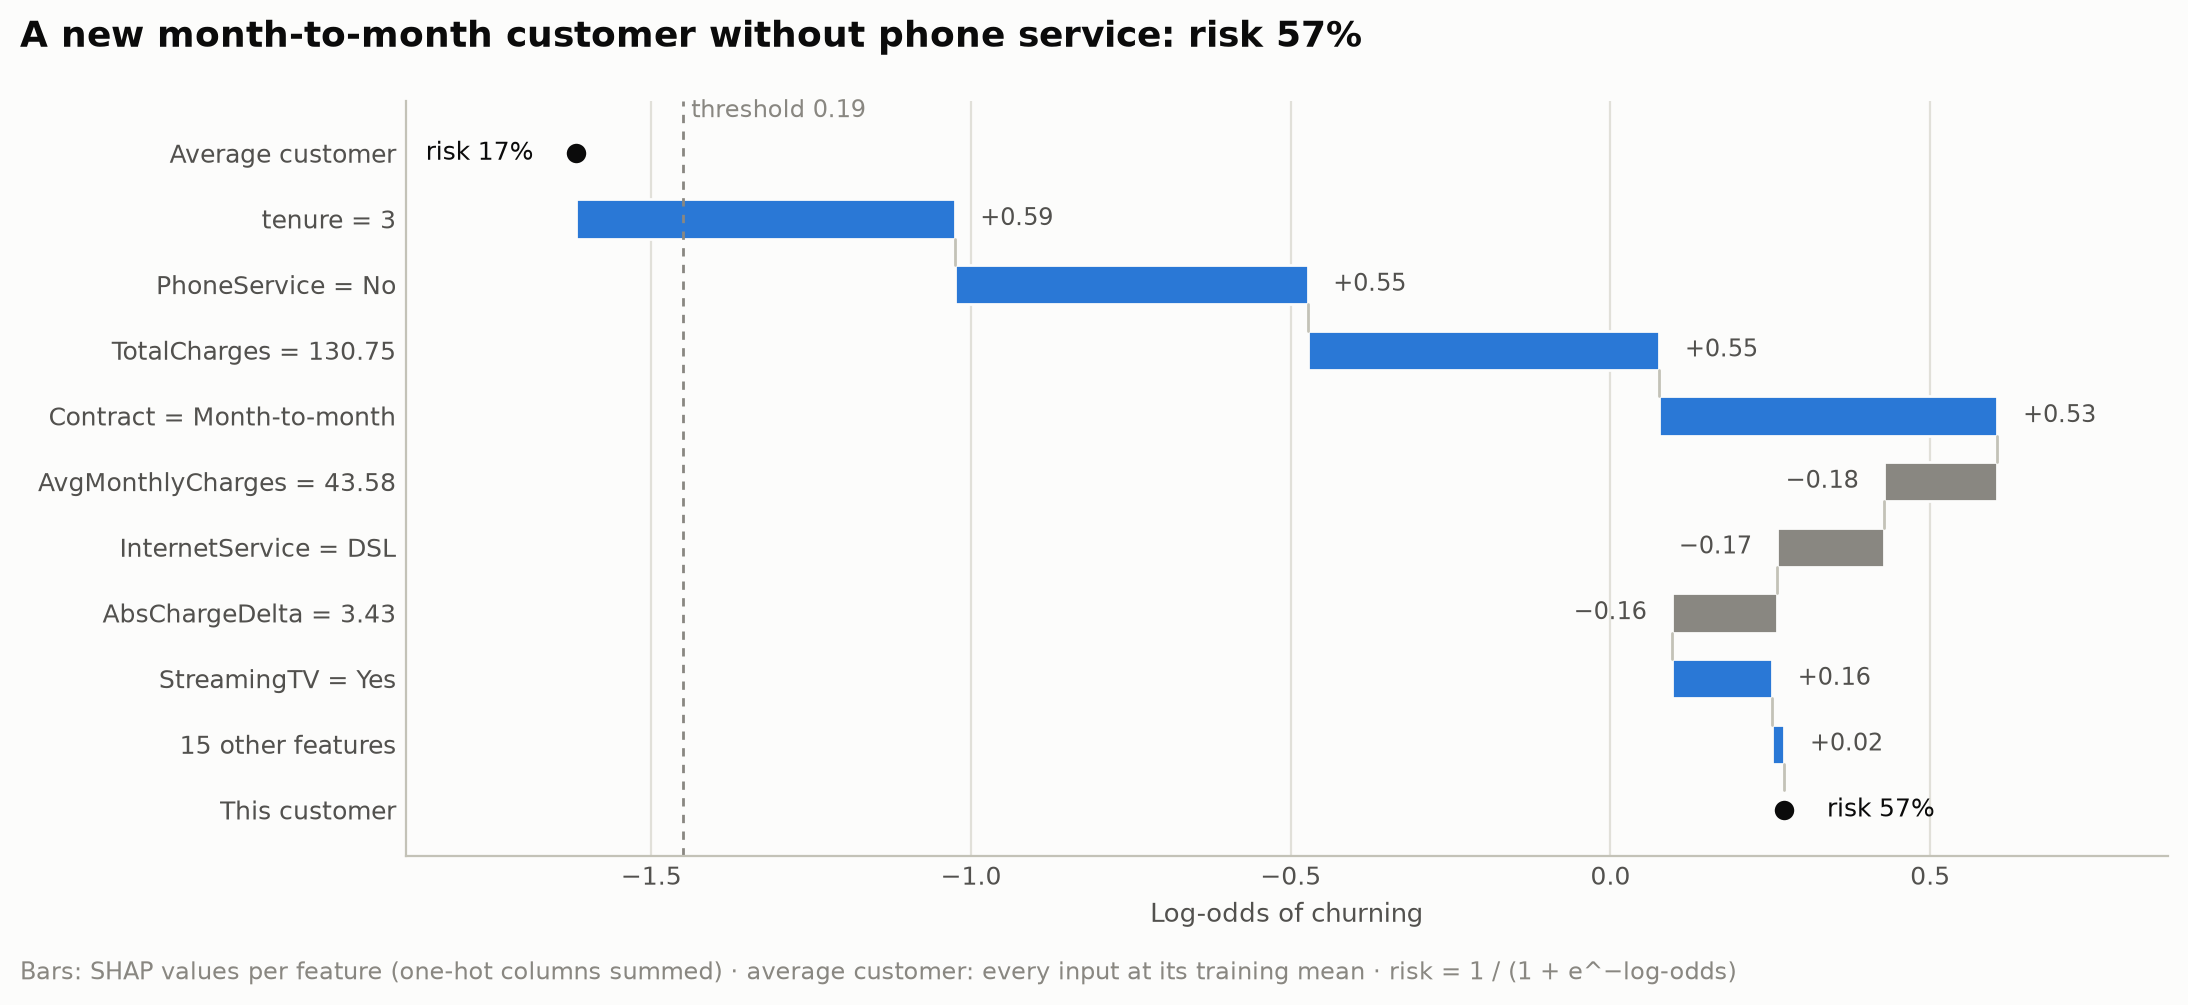

In [33]:
customer = typical_flagged_churner(y_test, proba, threshold)
plot_shap_waterfall(
    shap_values,
    customer,
    threshold,
    "A new month-to-month customer without phone service: risk 57%",
);

- **From 17 % to 57 %:** four features lift this customer far above the threshold: a tenure of only 3 months, the low total charges that come with it, the month-to-month contract and no phone service. DSL internet (rather than fiber optic) lowers the risk a little.
- **Average customer, not average risk:** the starting point (17 %) is the risk of a customer with every input at its mean. It is lower than the churn rate (26.5 %), as the log-odds scale is curved.
- **Why does "no phone service" raise the risk?** On its own, phone service shows no association with churn (section 2). The model reads it together with the monthly bill: at the same bill, a customer without phone service pays everything for internet services. Correlated inputs share their effects (section 8.3).
- **For marketing:** a new customer on a flexible contract; an offer of a longer contract addresses the main drivers.

### 8.3 Odds ratios

An odds ratio of 0.5 halves the odds of churning and 2 doubles them, with all other inputs held fixed. Numeric inputs are compared per standard deviation (after Yeo-Johnson), levels with the most common level of their feature. The intervals come from refitting the regression on 1,000 bootstrap samples of the training set; this takes about 20 seconds on 12 CPU cores.

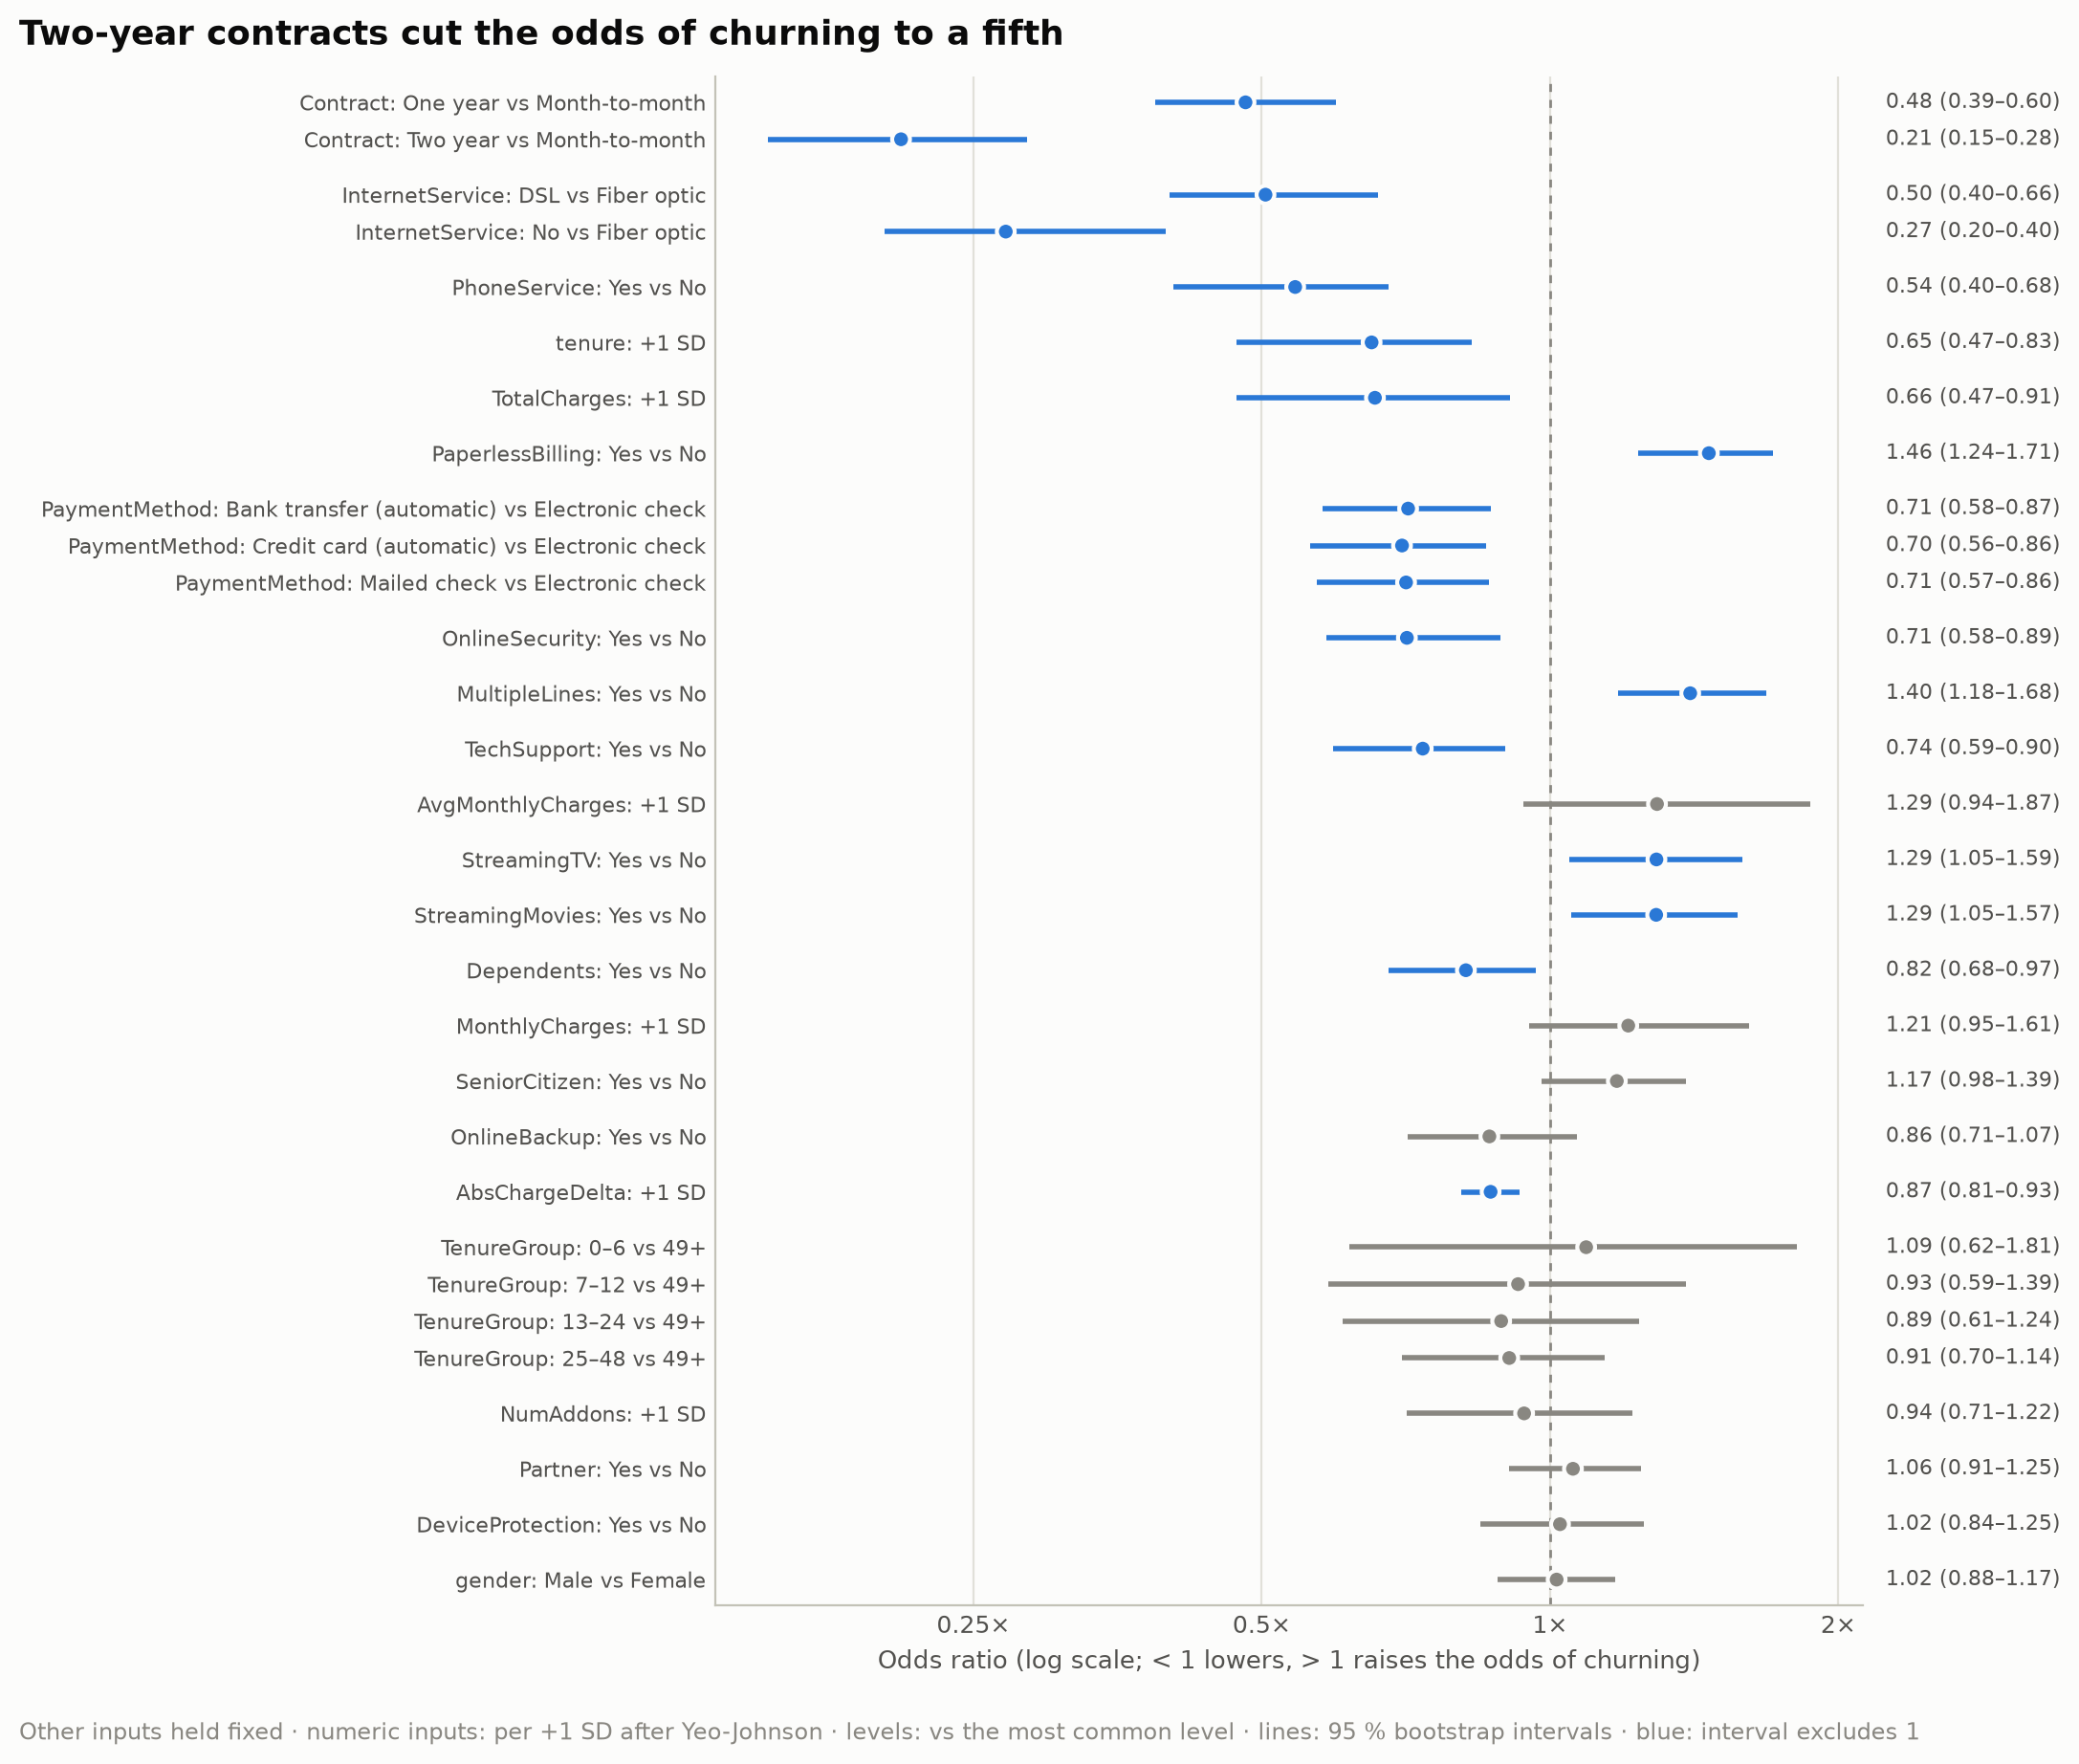

In [34]:
ratios = odds_ratios(final_pipeline, X_train, y_train)
plot_odds_ratios(ratios, "Two-year contracts cut the odds of churning to a fifth");

- **Contract:** two-year customers have 0.21× the odds of month-to-month customers, one-year customers 0.48×: the strongest effect.
- **Internet service:** DSL customers have half the odds of fiber-optic customers (0.50×), customers without internet 0.27×.
- **Add-ons and billing:** online security (0.71×) and tech support (0.74×) lower the odds; paperless billing (1.46×), multiple lines (1.40×) and streaming (1.29×) raise them. Automatic payments and mailed checks have about 0.7× the odds of electronic checks.
- **Correlated inputs:** tenure, the charges and the tenure groups overlap, so the model splits their effect among them: the tenure groups show no clear effect next to tenure, and phone service (0.54×) mostly corrects the effect of the monthly charges. Together they matter a lot (section 8.1); read them as a group, not one by one.
- **No effect:** gender, partner and device protection (intervals around 1).

**Caveat:** SHAP values and odds ratios describe associations in past data, not causes. Whether, say, an offer of a longer contract actually prevents churn is best tested with a controlled experiment (e.g. an A/B test).

## 9. Serving the model via a REST API